# Phase 10 — KUB Fair Baseline Model Comparison

Display-only finalized TRAIN/VAL results. **TEST was not accessed.** No cell trains or evaluates a model.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd().resolve(); ROOT=ROOT.parent if ROOT.name=='notebooks' else ROOT
T=ROOT/'reports/tables'; F=ROOT/'reports/figures/phase10_kub_comparison'; Q=ROOT/'reports/qualitative/phase10_kub_comparison'
comparison=pd.read_csv(T/'phase10_kub_model_comparison.csv')
fairness=pd.read_csv(T/'phase10_kub_fairness_table.csv')
assert len(comparison)==4
print('Governance: phase4_v2; TEST locked; TEST metrics NONE; external data not used')

Governance: phase4_v2; TEST locked; TEST metrics NONE; external data not used


## Fairness and model parameters

In [2]:
display(fairness)
display(comparison[['model','parameters','epochs_completed','best_epoch','physical_batch','effective_batch']])

,model,seed,resolution,optimizer,learning_rate,weight_decay,scheduler,loss,threshold,max_epochs,patience,preprocessing,augmentation,physical_batch,effective_batch,initialization_policy,selection_metric
0,U-Net,42,512,AdamW,0.0001,0.0001,CosineAnnealingLR,0.5 BCEWithLogitsLoss + 0.5 DiceLoss,0.5,100,15,aspect-ratio resize + symmetric square padding,HFlip p=.5; rotation ±5°; brightness/contrast ...,4,4,random Kaiming; no pretrained weights,true per-image VAL macro Dice
1,Attention U-Net,42,512,AdamW,0.0001,0.0001,CosineAnnealingLR,0.5 BCEWithLogitsLoss + 0.5 DiceLoss,0.5,100,15,aspect-ratio resize + symmetric square padding,HFlip p=.5; rotation ±5°; brightness/contrast ...,4,4,random Kaiming; no pretrained weights,true per-image VAL macro Dice
2,UNet++,42,512,AdamW,0.0001,0.0001,CosineAnnealingLR,0.5 BCEWithLogitsLoss + 0.5 DiceLoss,0.5,100,15,aspect-ratio resize + symmetric square padding,HFlip p=.5; rotation ±5°; brightness/contrast ...,4,4,random Kaiming; no pretrained weights,true per-image VAL macro Dice
3,DeepLabV3+,42,512,AdamW,0.0001,0.0001,CosineAnnealingLR,0.5 BCEWithLogitsLoss + 0.5 DiceLoss,0.5,100,15,aspect-ratio resize + symmetric square padding,HFlip p=.5; rotation ±5°; brightness/contrast ...,4,4,random Kaiming; no pretrained weights,true per-image VAL macro Dice


,model,parameters,epochs_completed,best_epoch,physical_batch,effective_batch
0,U-Net,7762465,62,47,4,4
1,Attention U-Net,7850709,92,77,4,4
2,UNet++,9159105,92,77,4,4
3,DeepLabV3+,40340769,52,37,4,4


## Overall comparison and HD95

,model,macro_dice,macro_iou,macro_precision,macro_recall,micro_dice,micro_iou,median_valid_hd95,mean_valid_hd95,empty_prediction_rate
0,U-Net,0.745544,0.631643,0.799446,0.765422,0.838204,0.721473,40.380669,53.611312,0.028269
1,Attention U-Net,0.753014,0.637711,0.793537,0.774175,0.832312,0.712786,40.266586,51.152991,0.017668
2,UNet++,0.762494,0.651495,0.822798,0.775599,0.843685,0.729633,35.510562,48.093780,0.028269
3,DeepLabV3+,0.748787,0.643457,0.783811,0.783367,0.867048,0.765300,34.876920,49.935926,0.028269


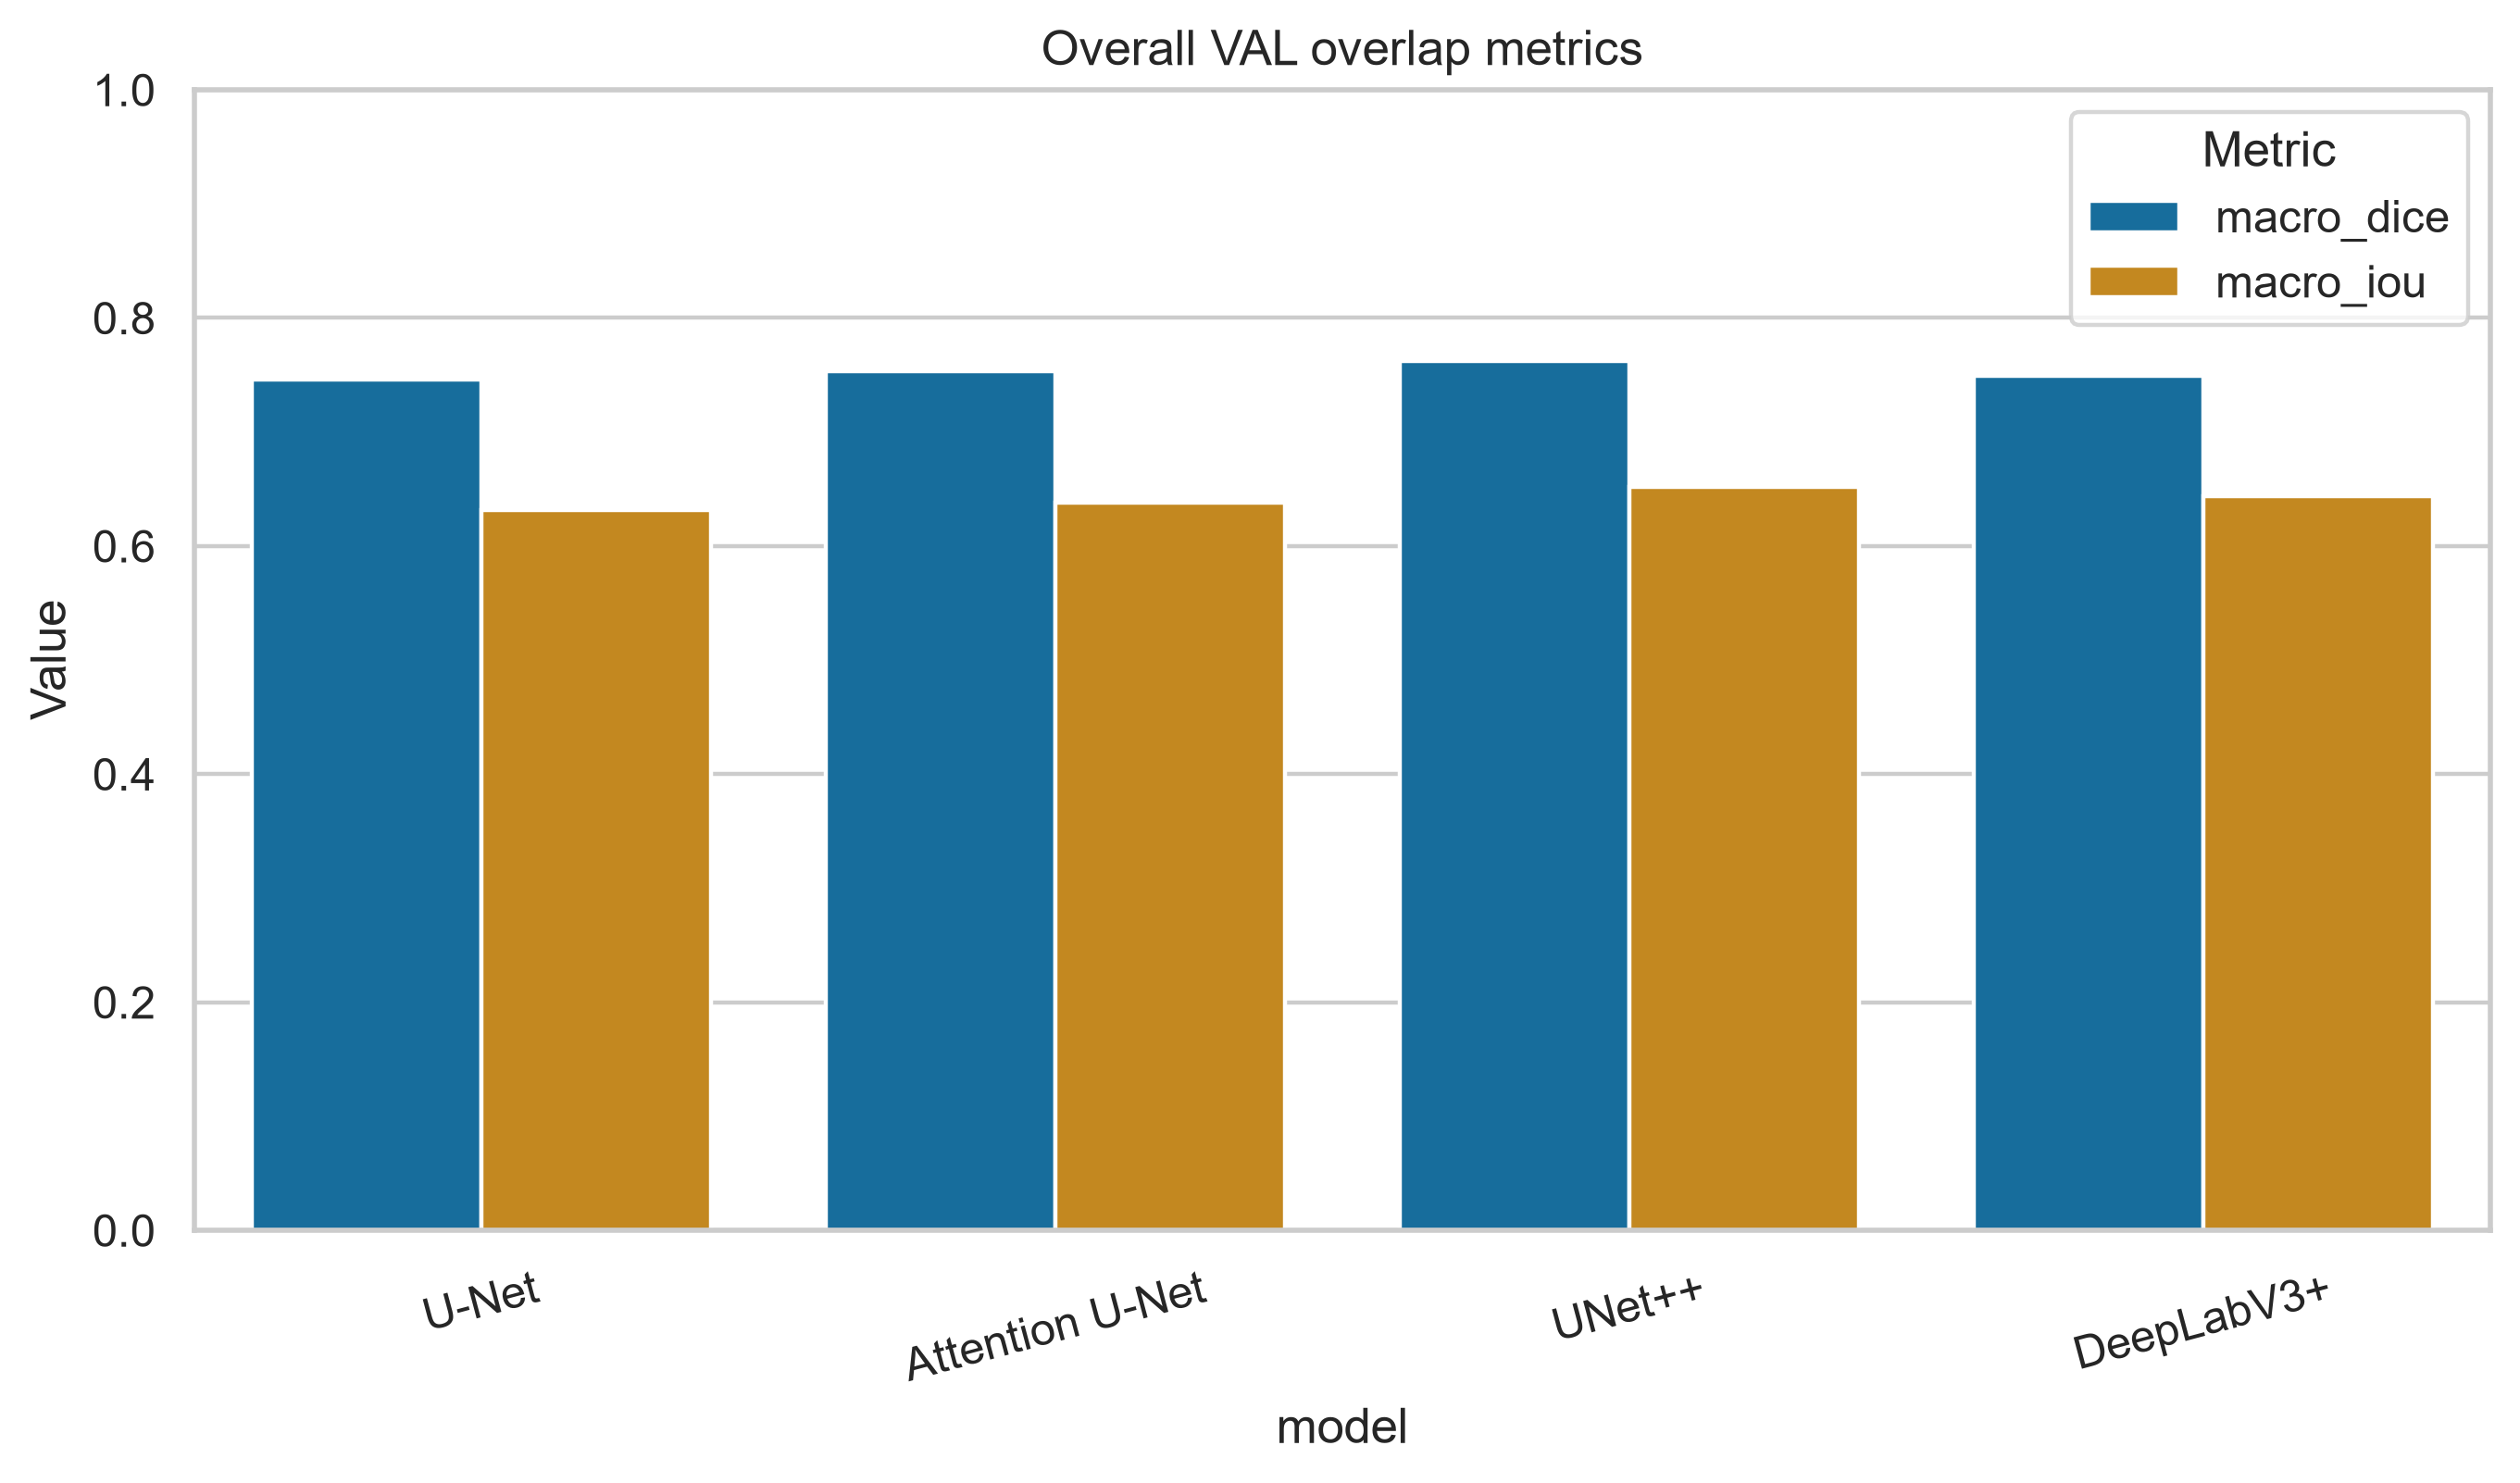

In [3]:
display(comparison[['model','macro_dice','macro_iou','macro_precision','macro_recall','micro_dice','micro_iou','median_valid_hd95','mean_valid_hd95','empty_prediction_rate']])
display(Image(filename=str(F/'phase10_overall_dice_iou.png'),width=950))

## FOV comparison

,model,full_field_dice,roi_crop_dice
0,U-Net,0.613015,0.824911
1,Attention U-Net,0.643275,0.818733
2,UNet++,0.652776,0.828201
3,DeepLabV3+,0.561354,0.861035


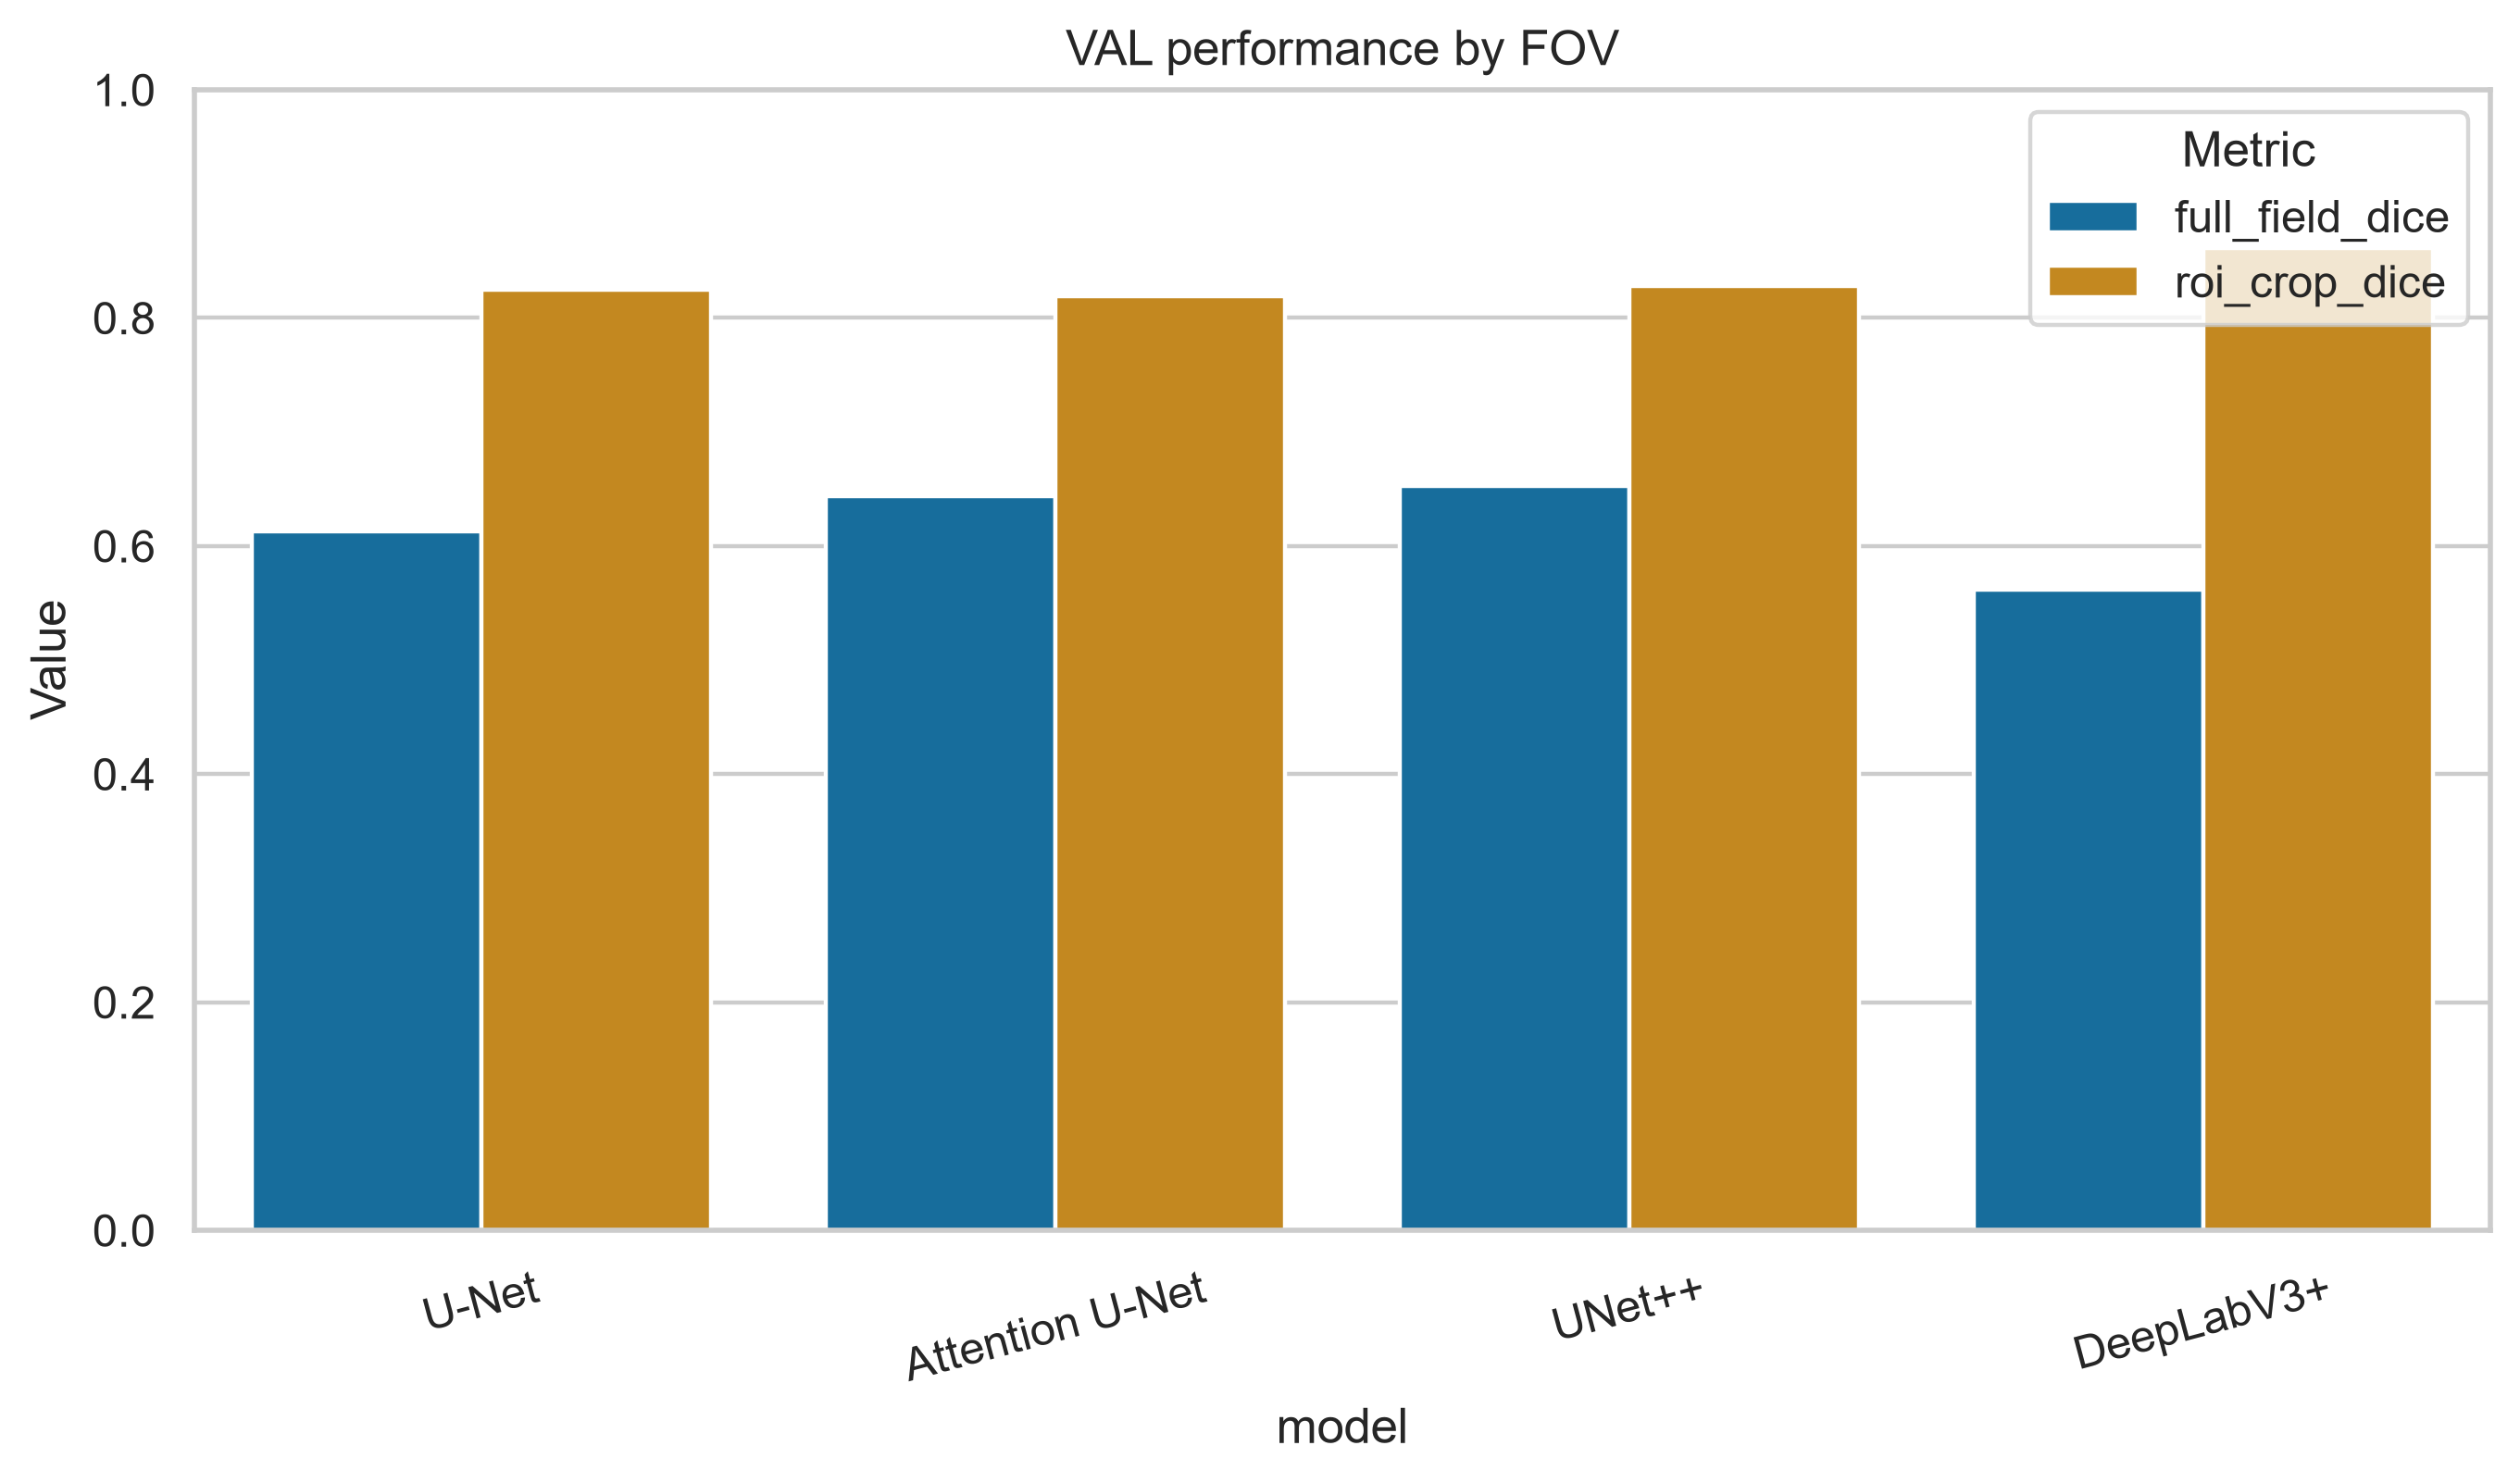

In [4]:
display(comparison[['model','full_field_dice','roi_crop_dice']])
display(Image(filename=str(F/'phase10_fov_performance.png'),width=950))

## Category comparison

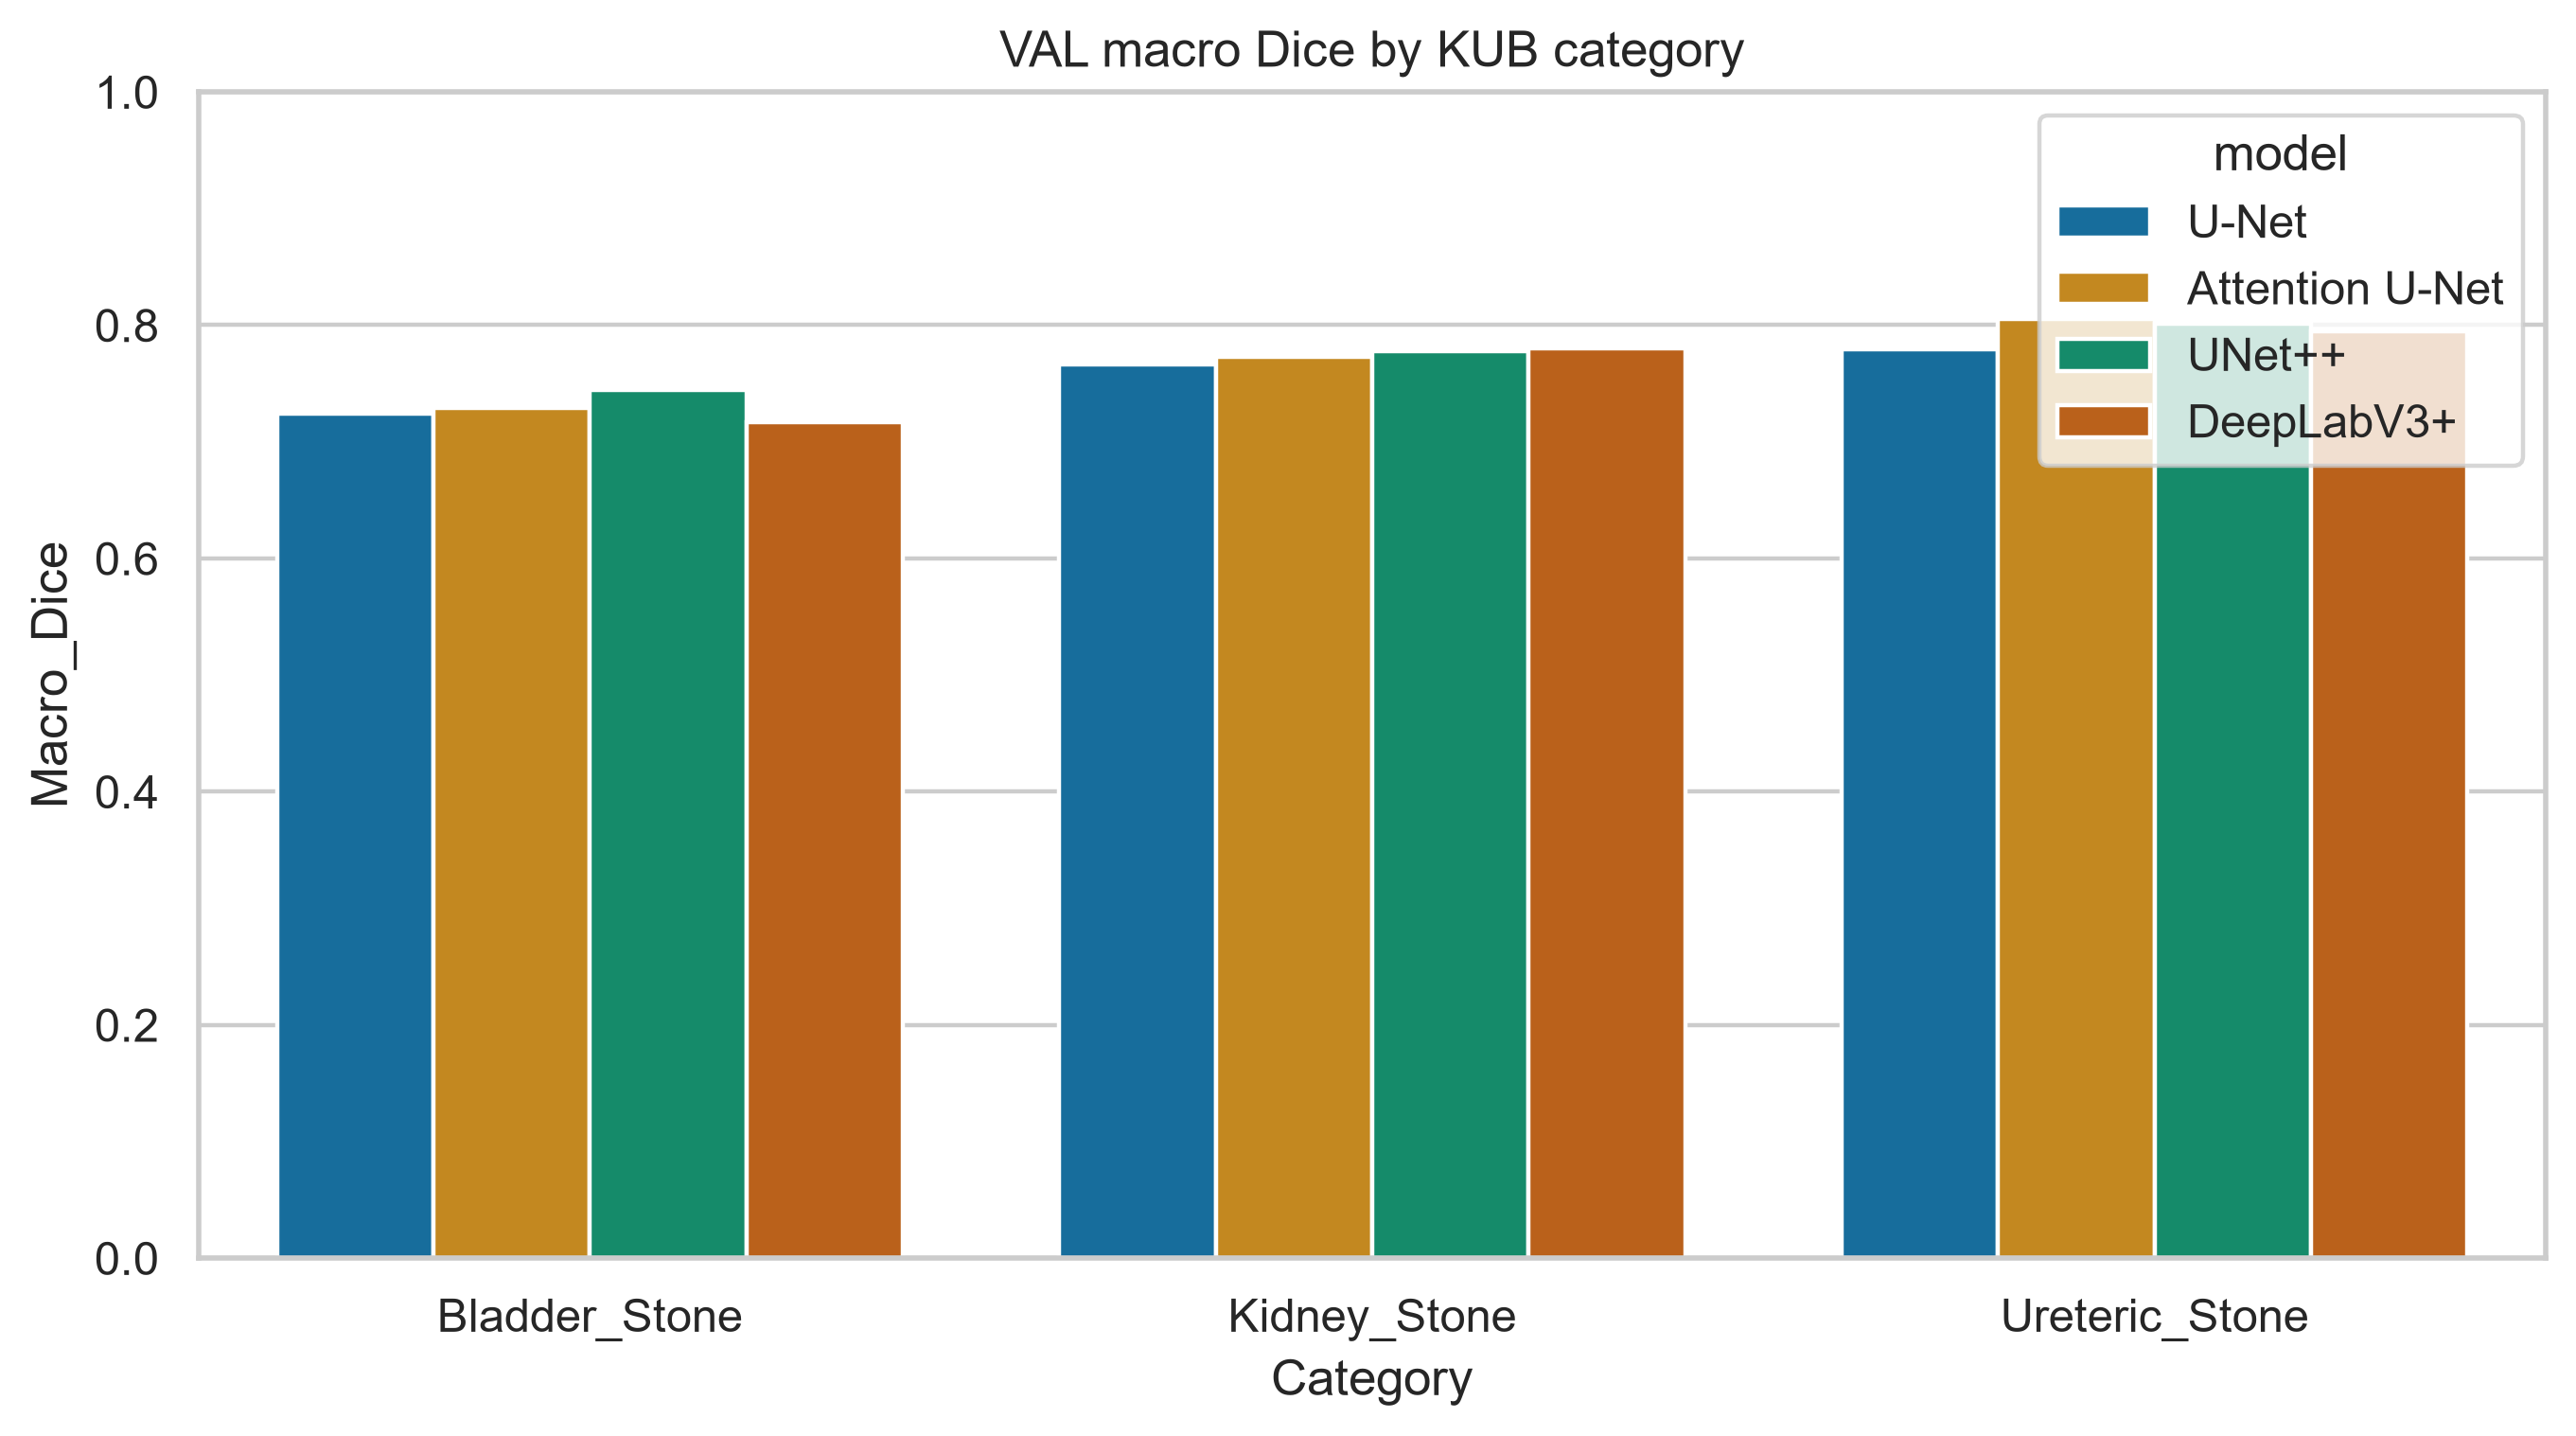

In [5]:
display(Image(filename=str(F/'phase10_category_dice.png'),width=950))

## Frozen original-space size comparison

,model,tiny_object_recall,small_object_recall,medium_object_recall,large_object_recall
0,U-Net,0.753425,0.827586,0.805556,0.944444
1,Attention U-Net,0.753425,0.862069,0.805556,0.944444
2,UNet++,0.780822,0.862069,0.888889,0.944444
3,DeepLabV3+,0.630137,0.827586,0.861111,0.944444


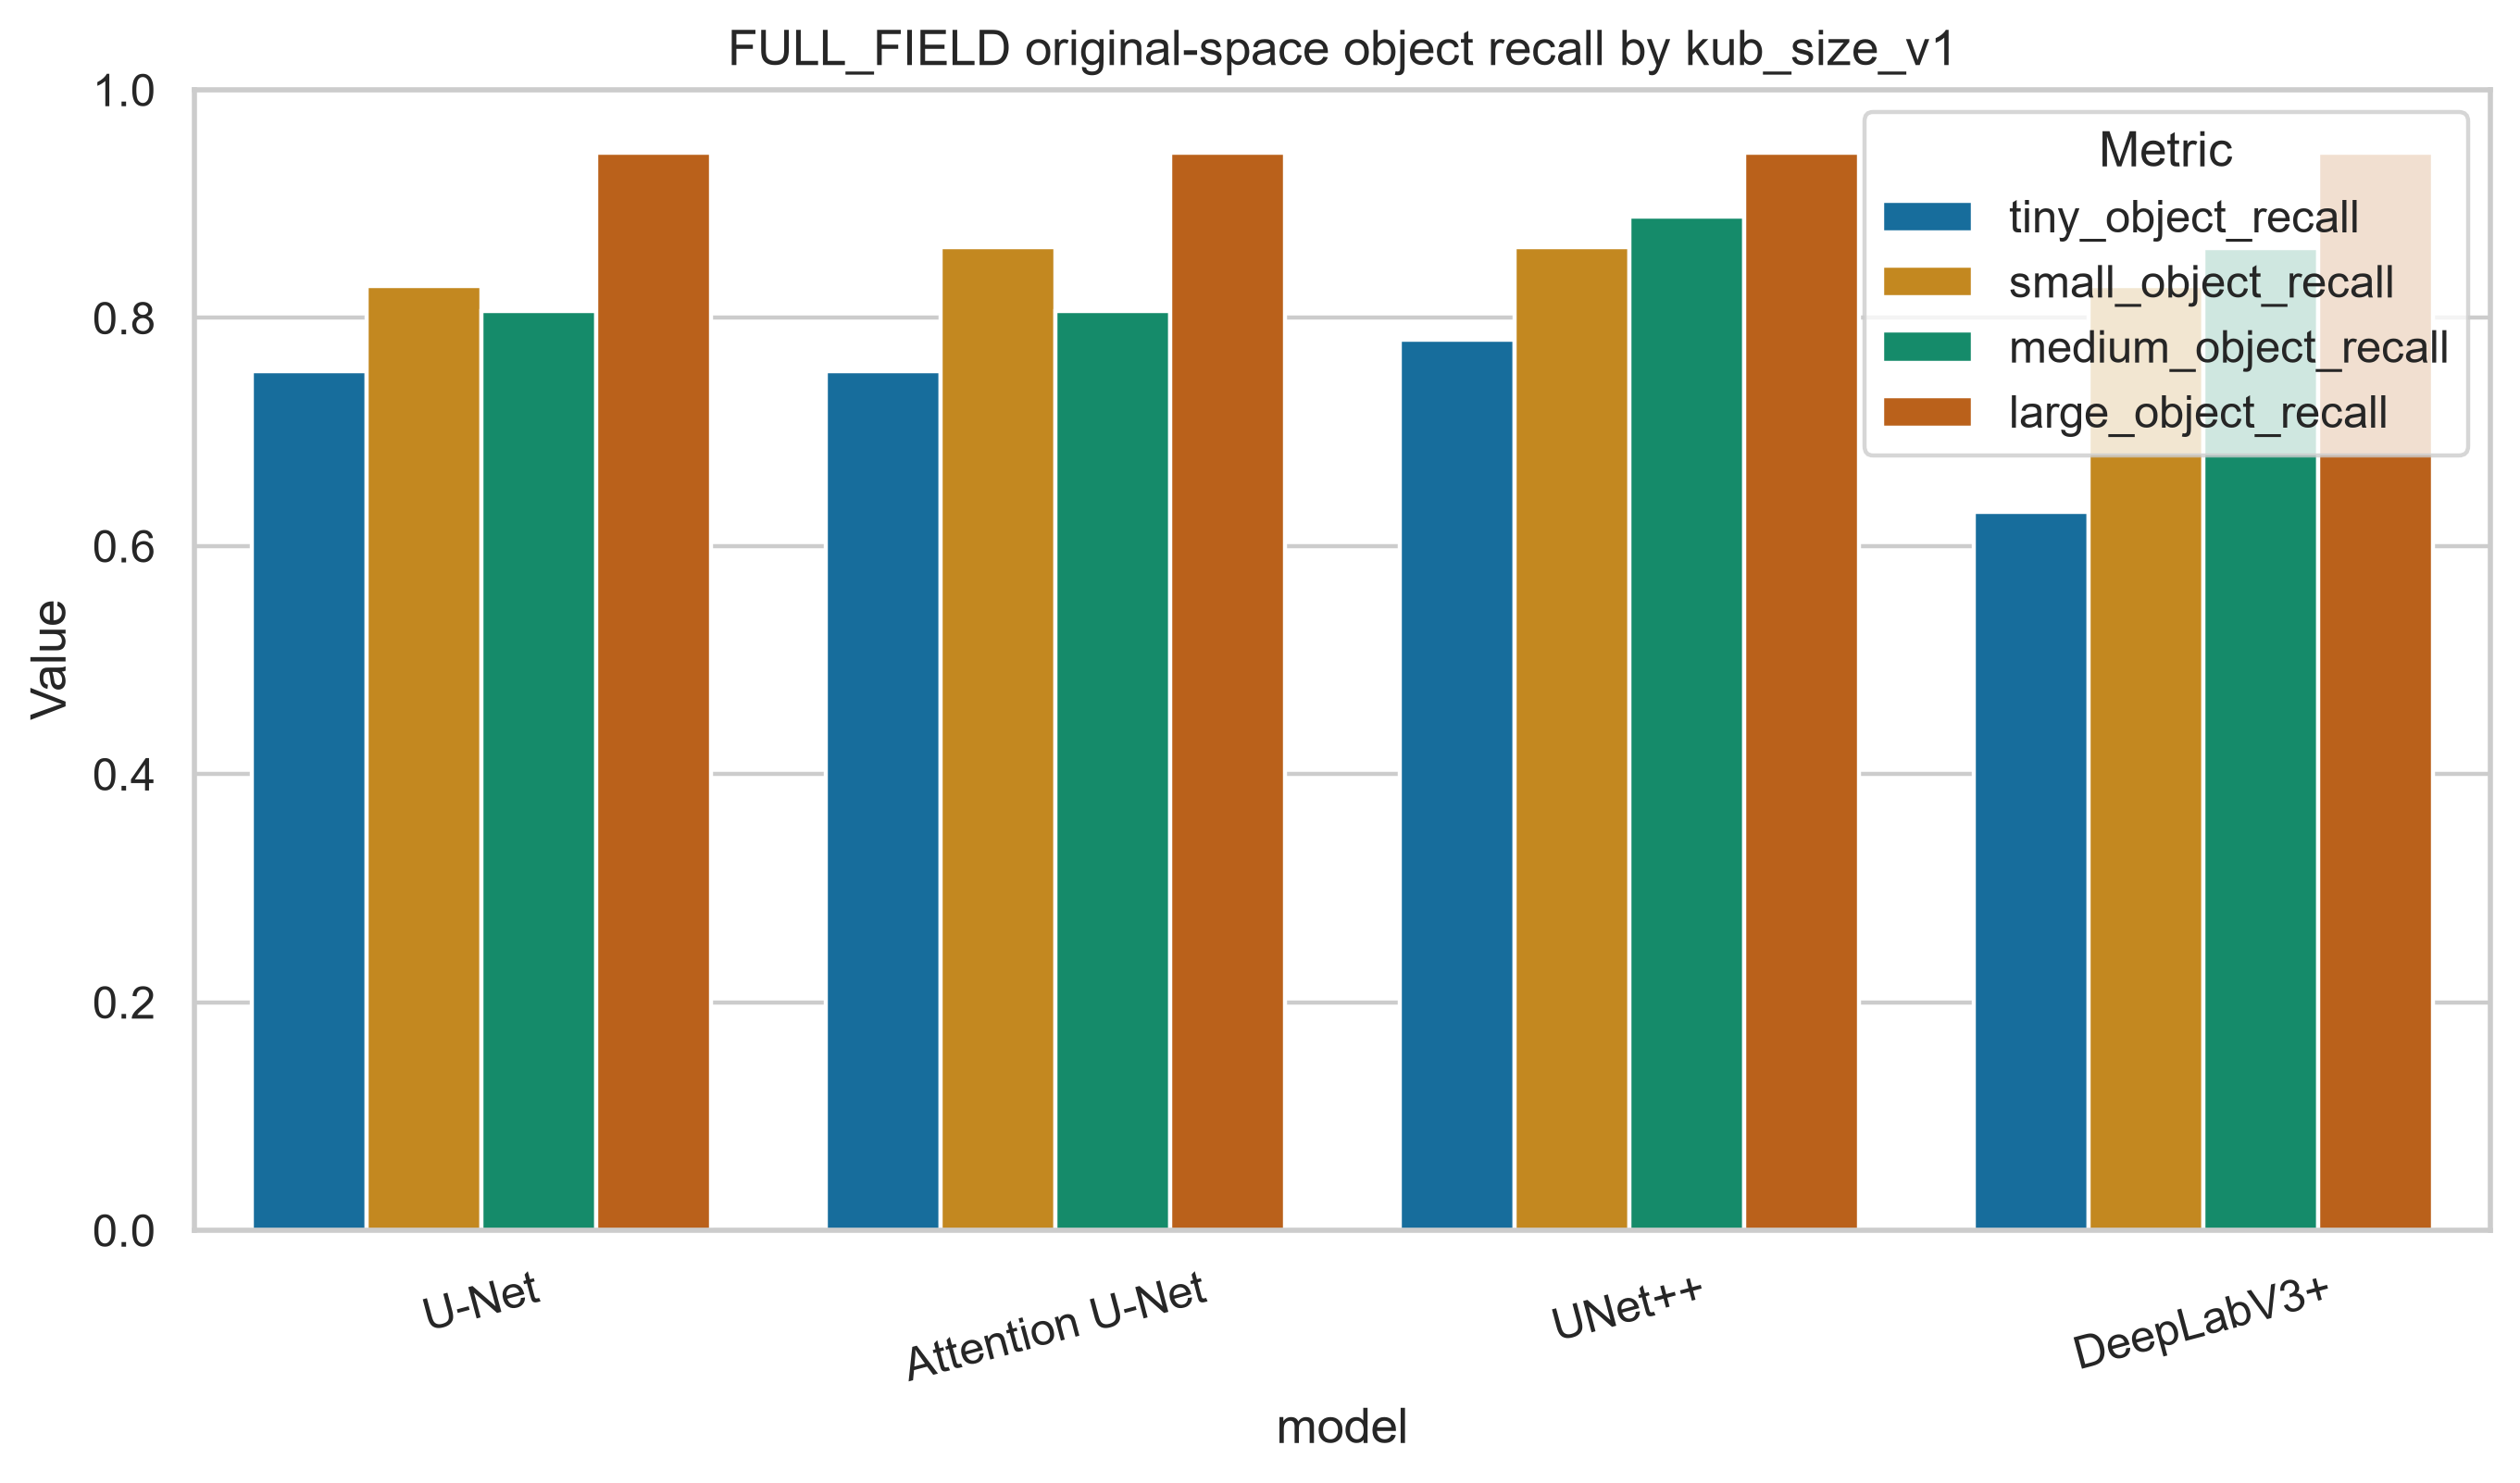

In [6]:
display(comparison[['model','tiny_object_recall','small_object_recall','medium_object_recall','large_object_recall']])
display(Image(filename=str(F/'phase10_size_recall.png'),width=950))

## Evaluation-space object metrics

,model,object_recall,missed_object_rate,fp_components_per_image
0,U-Net,0.903614,0.096386,9.003534
1,Attention U-Net,0.906627,0.093373,8.229682
2,UNet++,0.921687,0.078313,1.526502
3,DeepLabV3+,0.888554,0.111446,0.268551


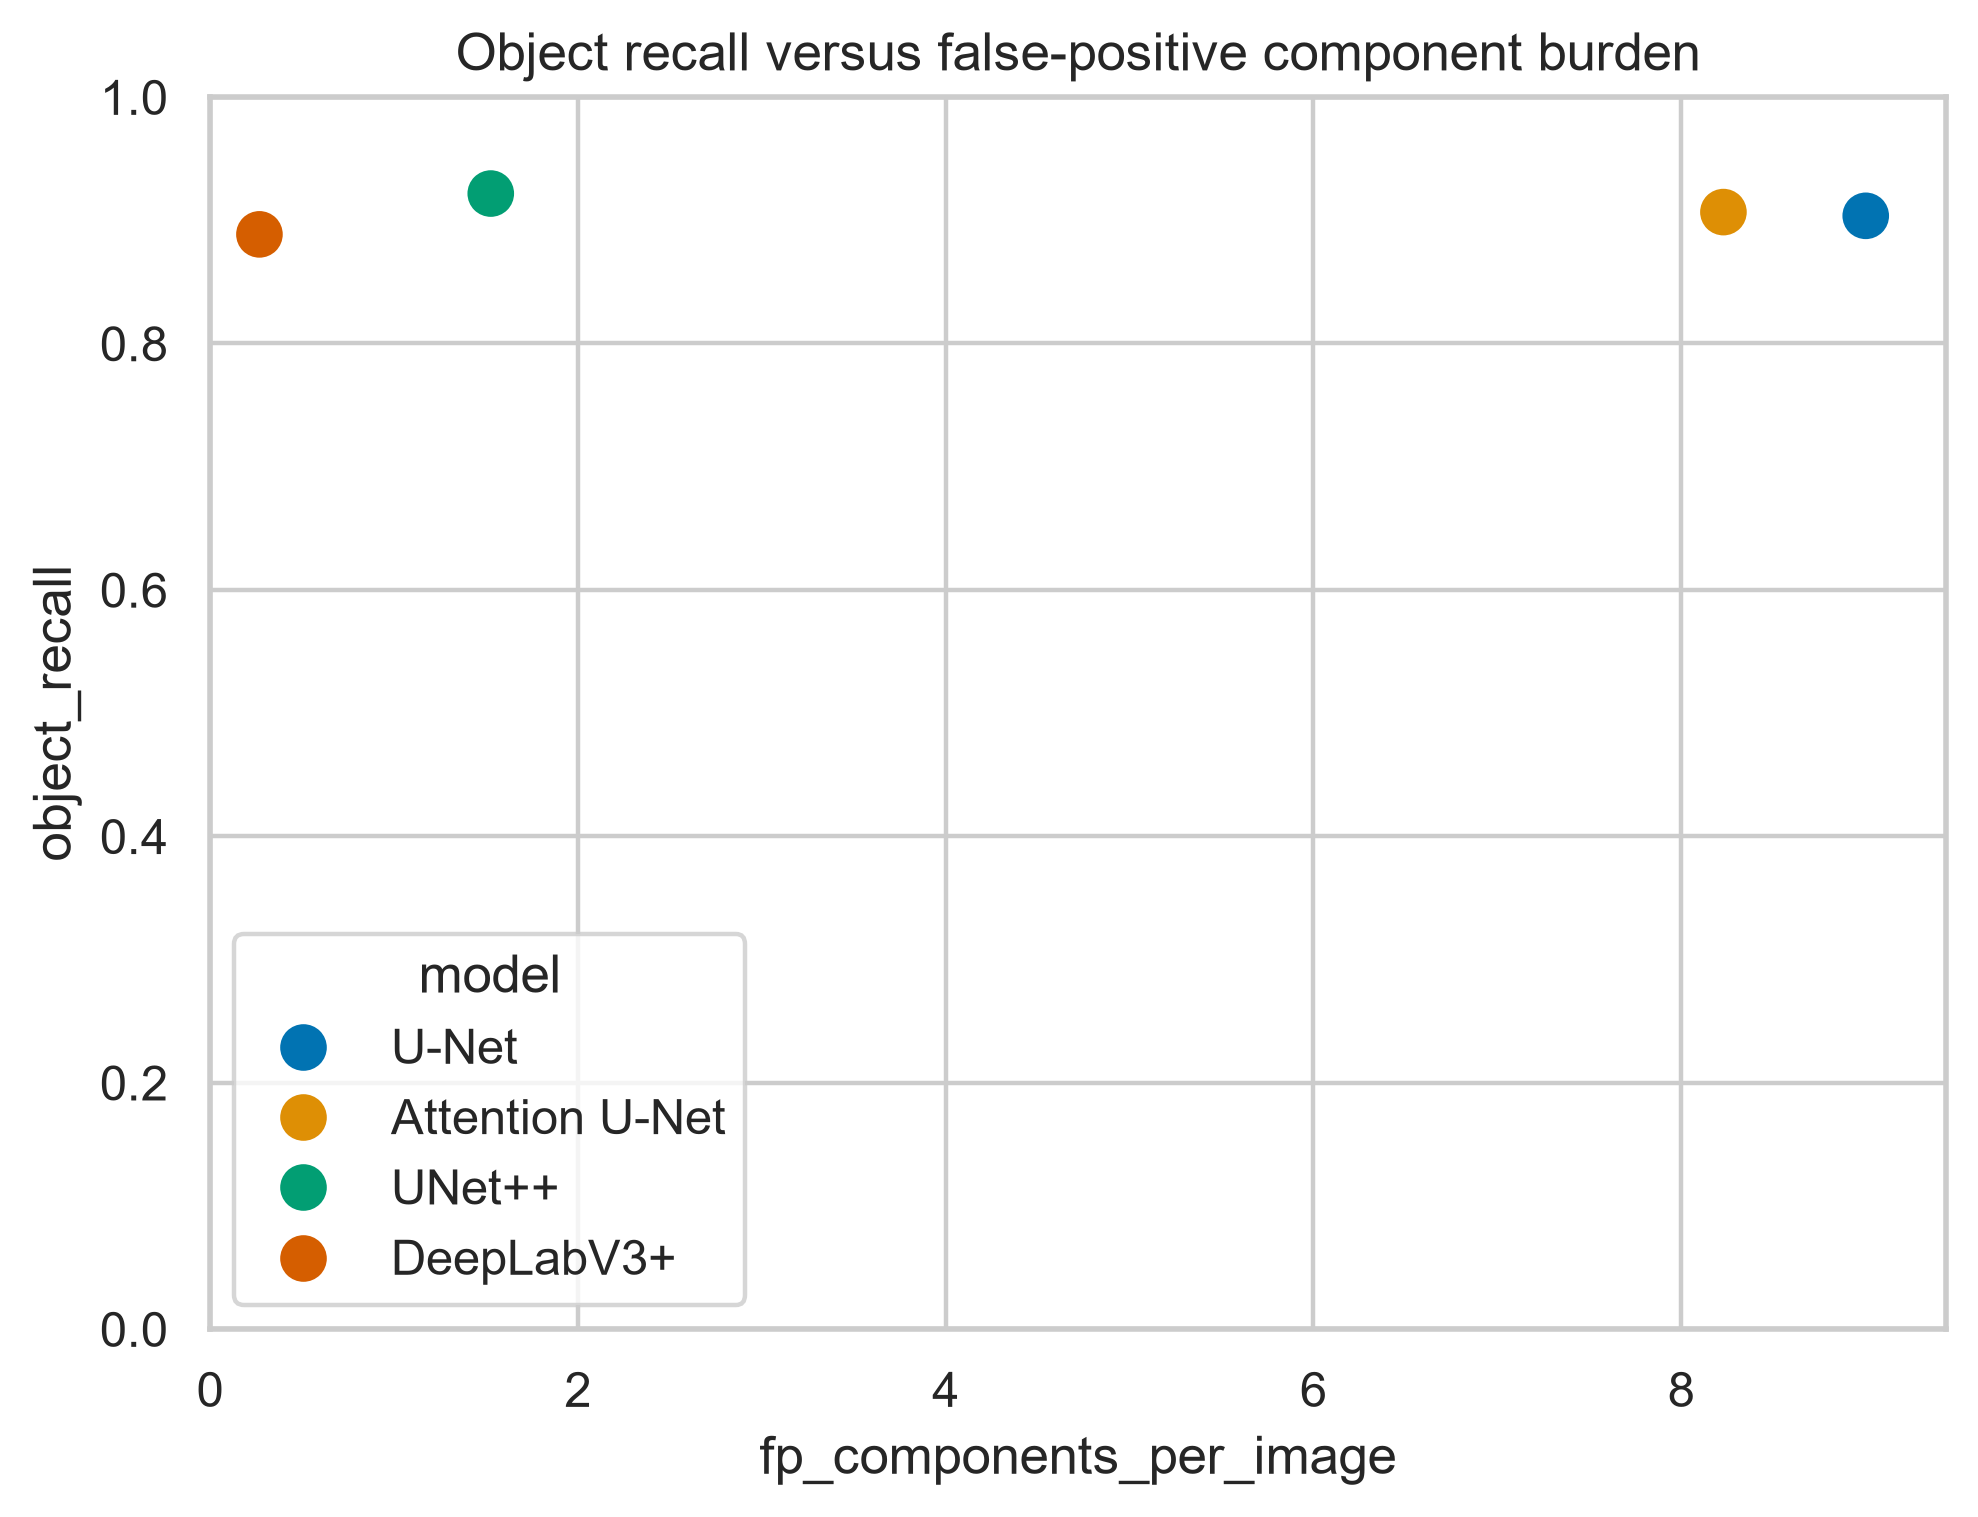

In [7]:
display(comparison[['model','object_recall','missed_object_rate','fp_components_per_image']])
display(Image(filename=str(F/'phase10_object_recall_vs_fp.png'),width=850))

## FULL_FIELD multi-component comparison

In [8]:
display(pd.read_csv(T/'phase10_kub_multicomponent_comparison.csv'))

,Model,Component_Group,N_Images,Macro_Dice,Original_GT_Components,Detected_Original_Components,Object_Recall,Missed_Object_Rate
0,U-Net,MULTI_COMPONENT,50,0.620885,100,79,0.790000,0.210000
1,U-Net,SINGLE_COMPONENT,56,0.605989,56,46,0.821429,0.178571
2,Attention U-Net,MULTI_COMPONENT,50,0.645733,100,79,0.790000,0.210000
3,Attention U-Net,SINGLE_COMPONENT,56,0.641080,56,47,0.839286,0.160714
4,UNet++,MULTI_COMPONENT,50,0.652216,100,82,0.820000,0.180000
5,UNet++,SINGLE_COMPONENT,56,0.653277,56,49,0.875000,0.125000
6,DeepLabV3+,MULTI_COMPONENT,50,0.561482,100,73,0.730000,0.270000
7,DeepLabV3+,SINGLE_COMPONENT,56,0.561240,56,45,0.803571,0.196429


## Efficiency and learning curves

,model,parameters,training_wall_time,mean_epoch_time,peak_gpu_allocated,peak_gpu_reserved
0,U-Net,7762465,4530.025540,73.064928,1723826176,2015363072
1,Attention U-Net,7850709,6472.539551,70.353691,2042458112,2415919104
2,UNet++,9159105,16292.141339,177.088493,5330496000,5997854720
3,DeepLabV3+,40340769,4872.600573,93.703857,2042002944,2246049792


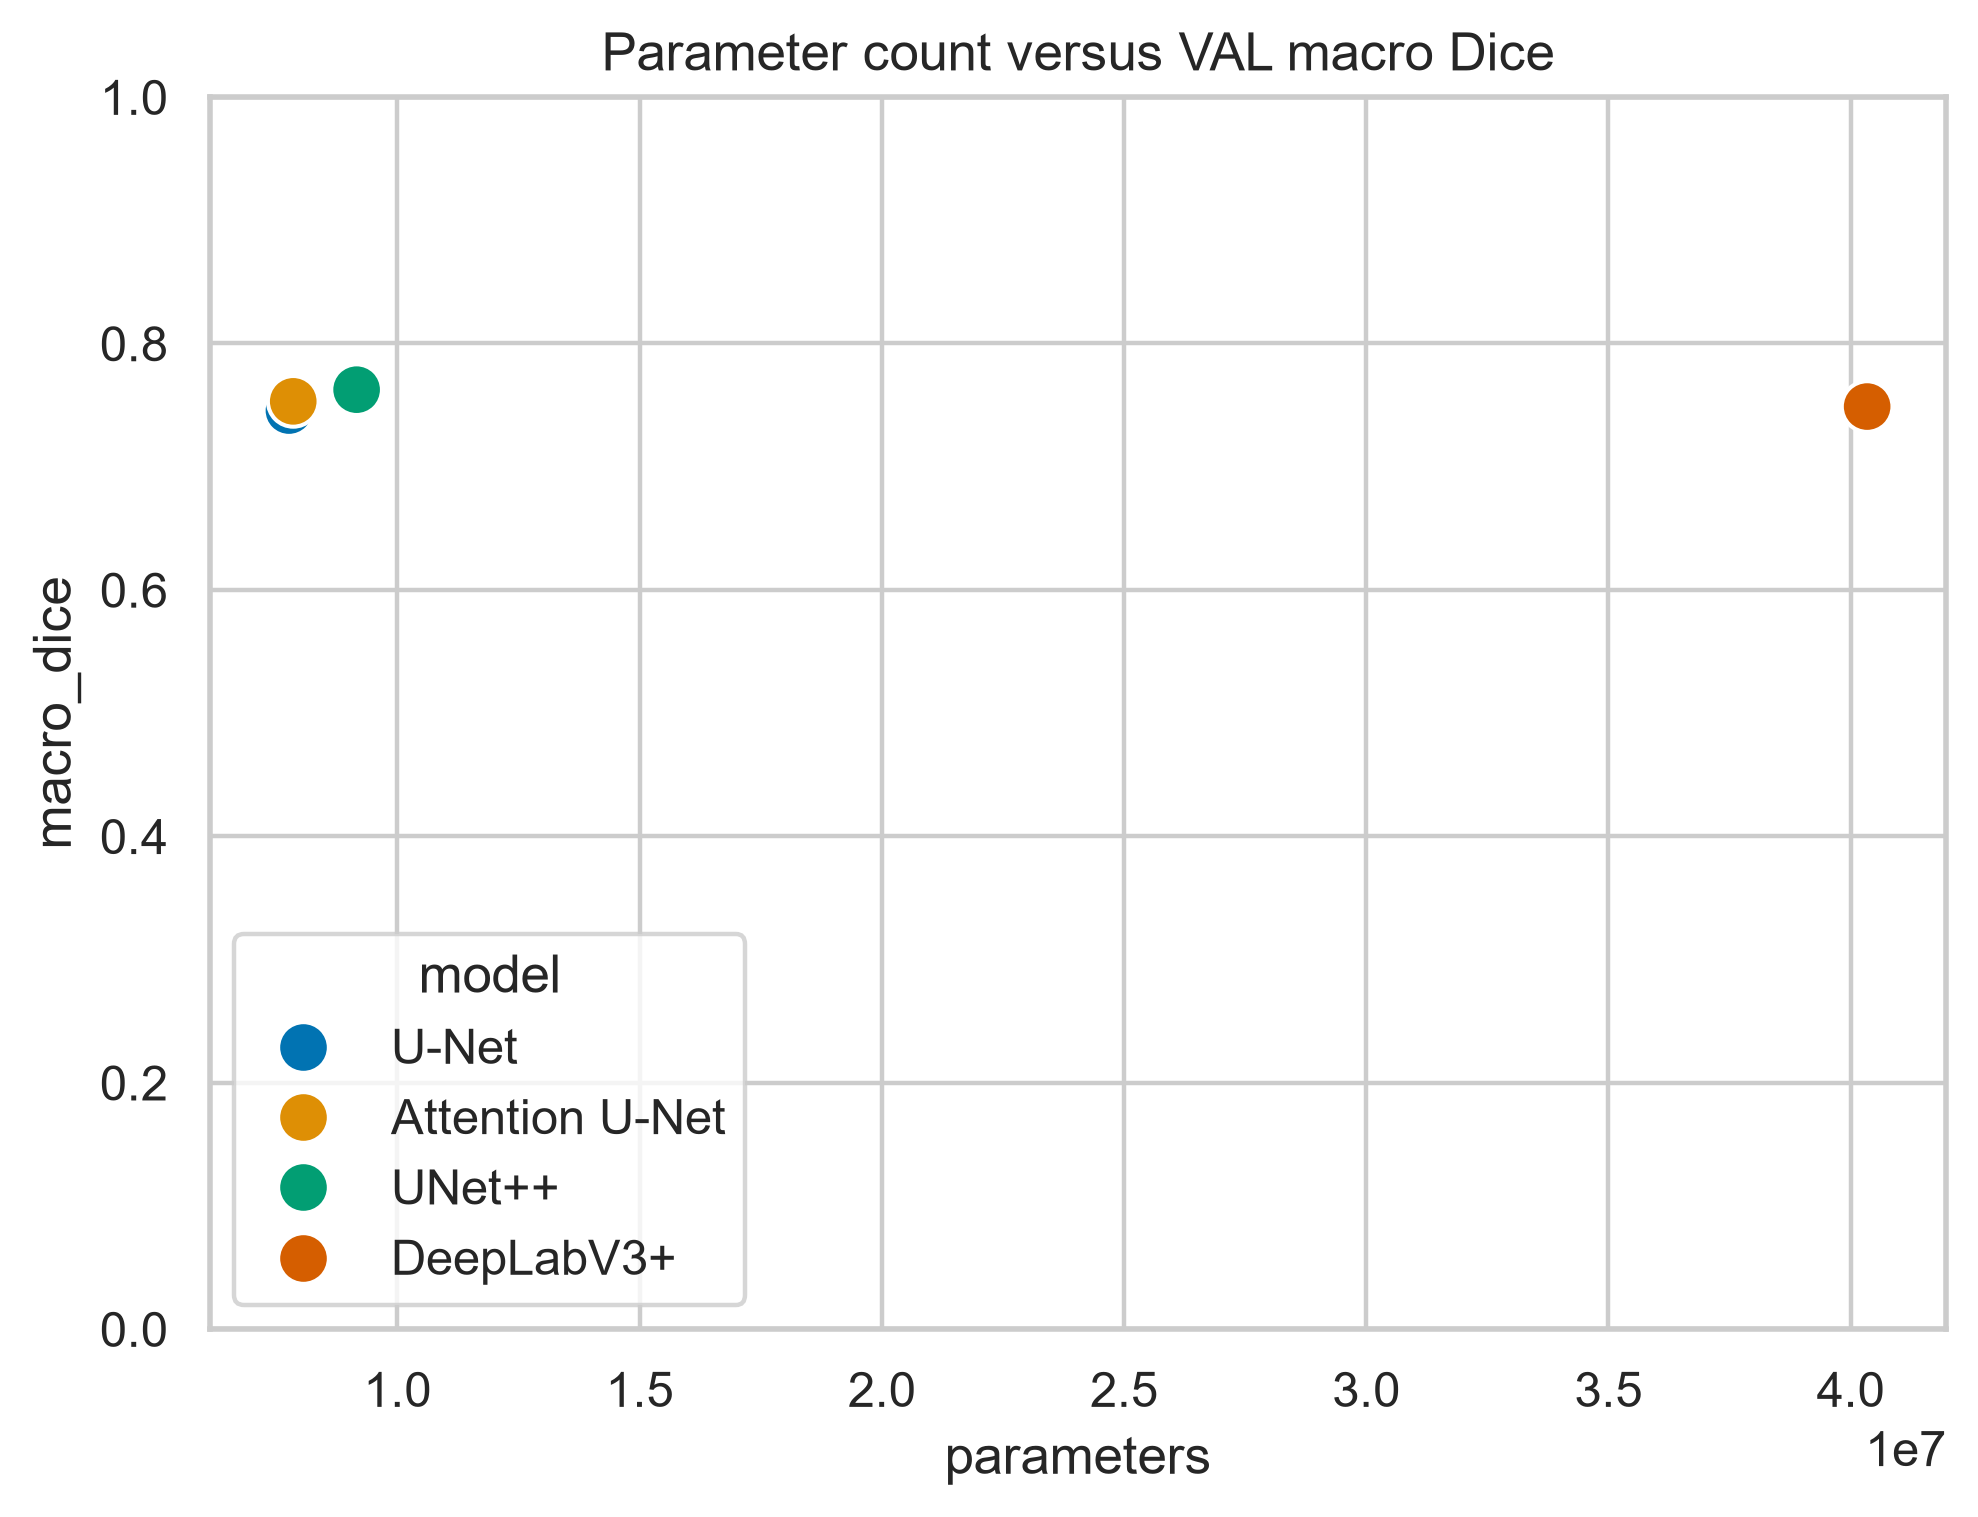

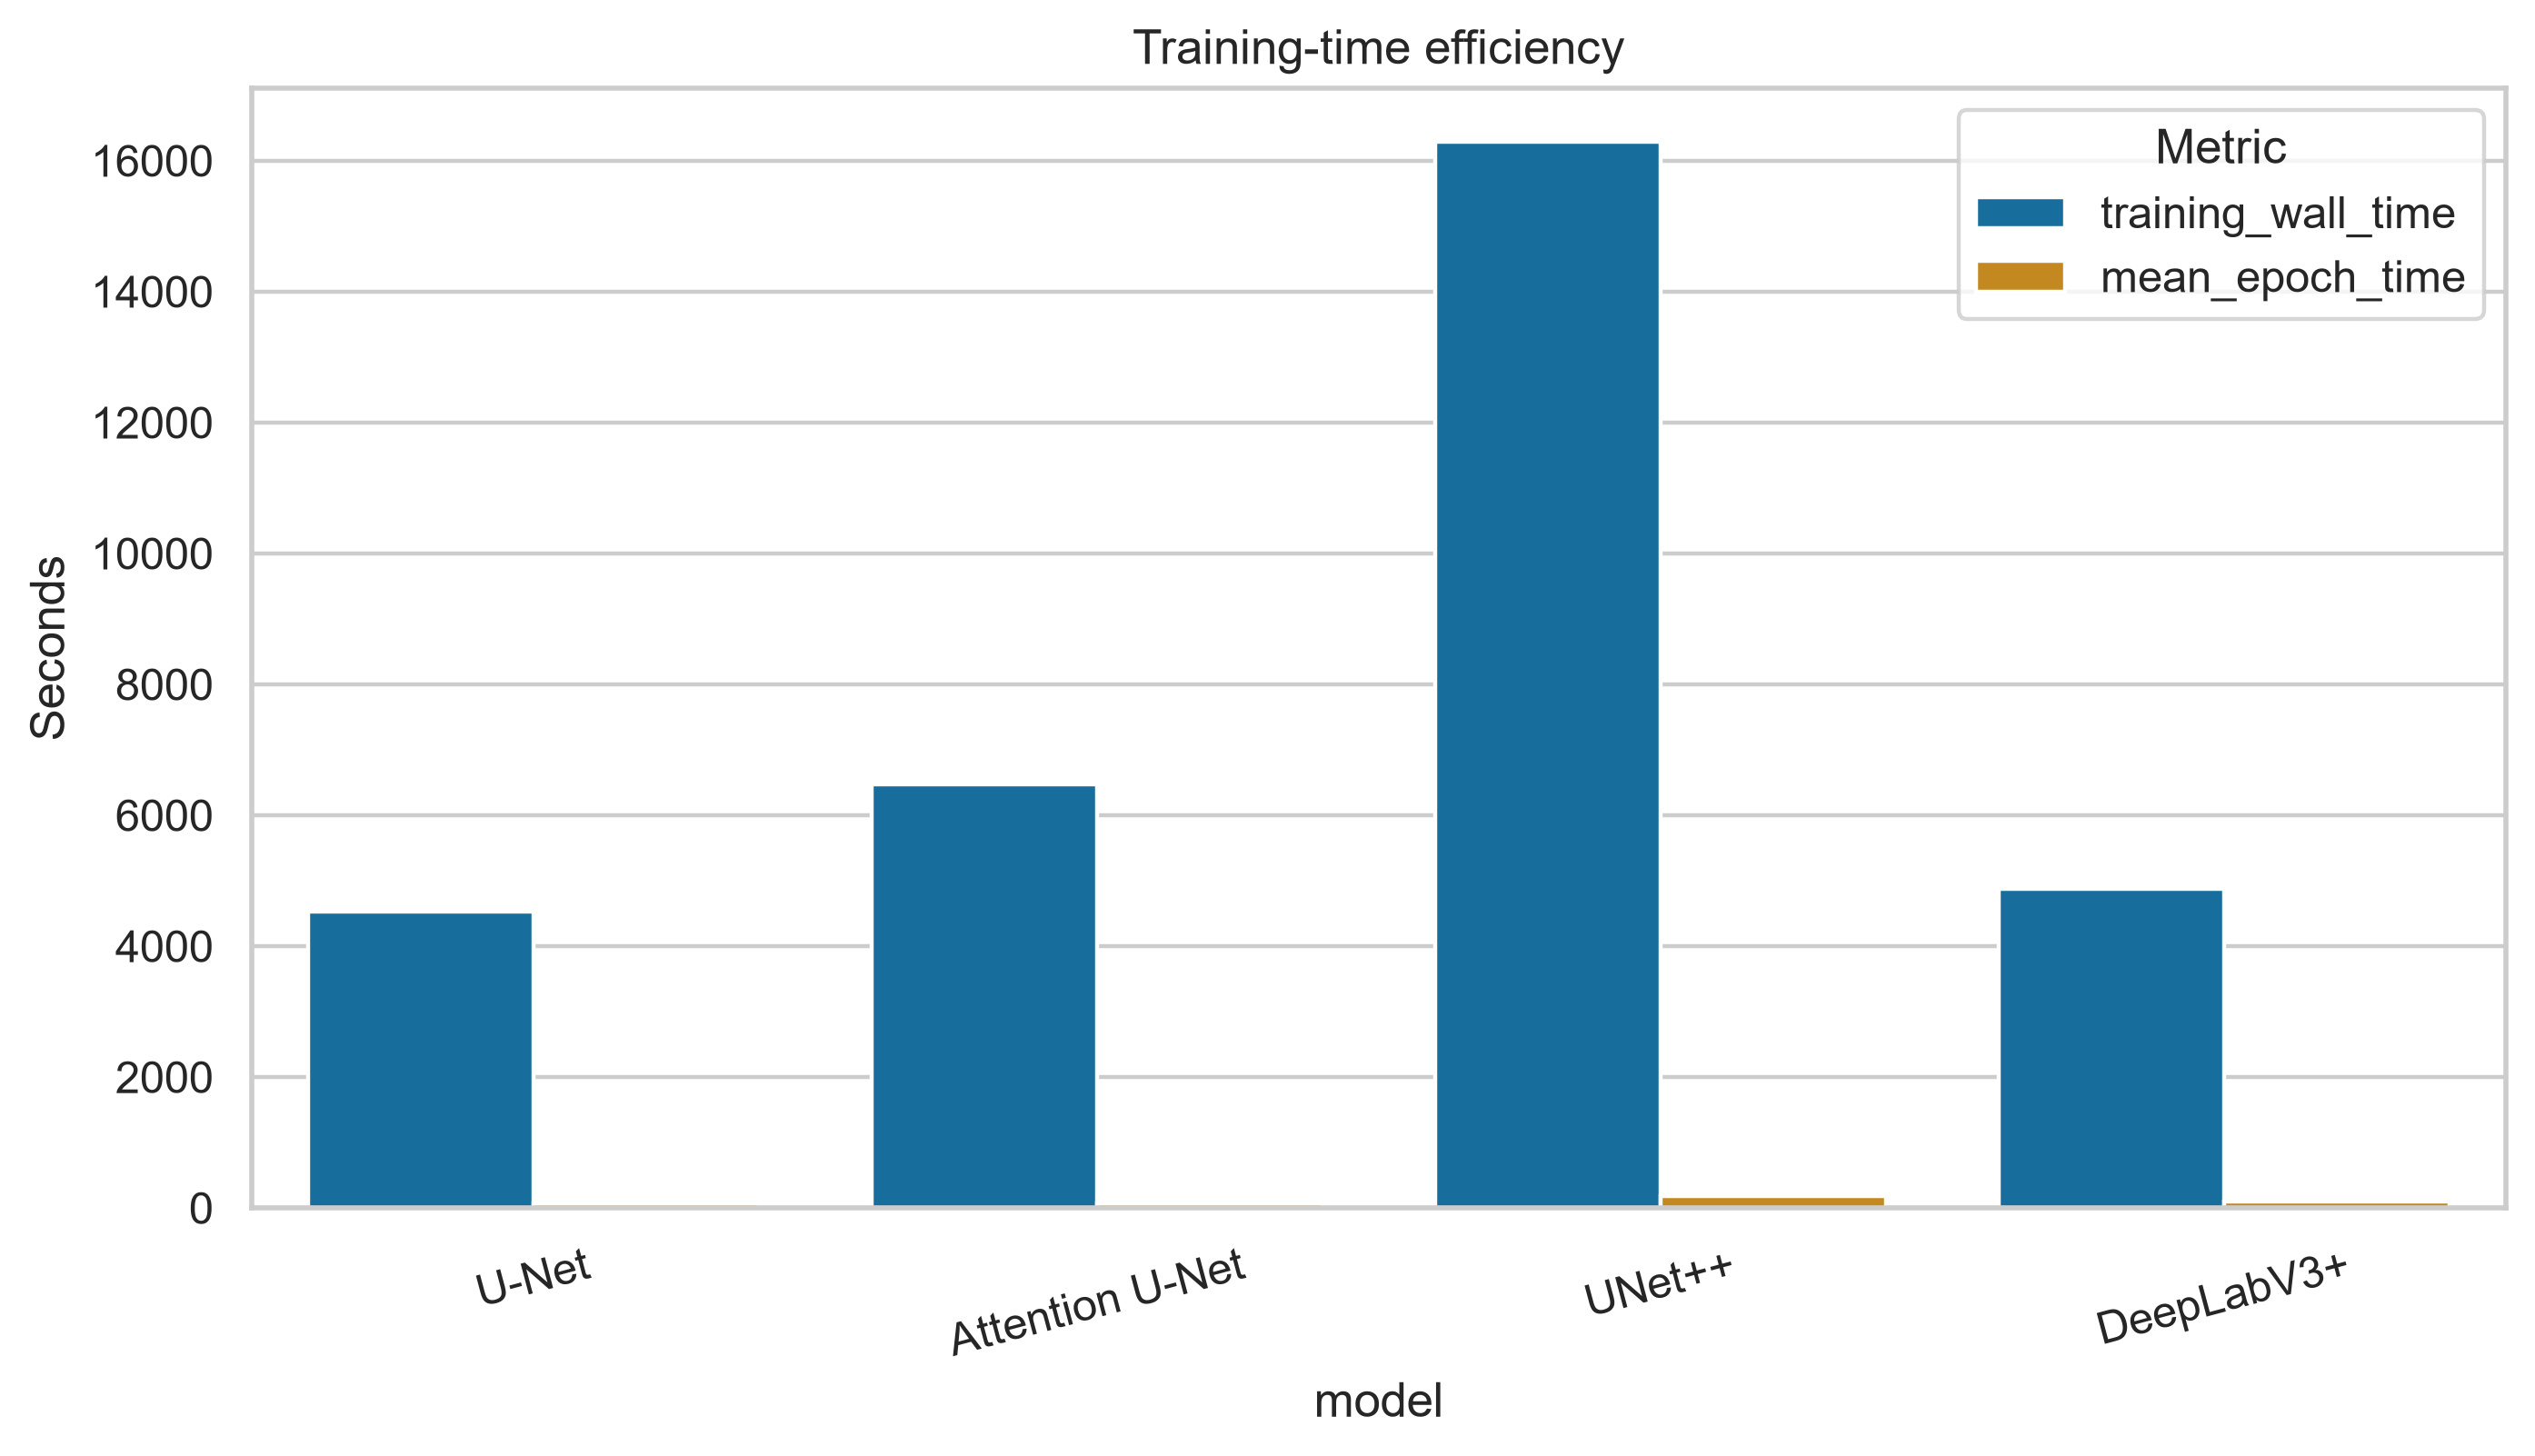

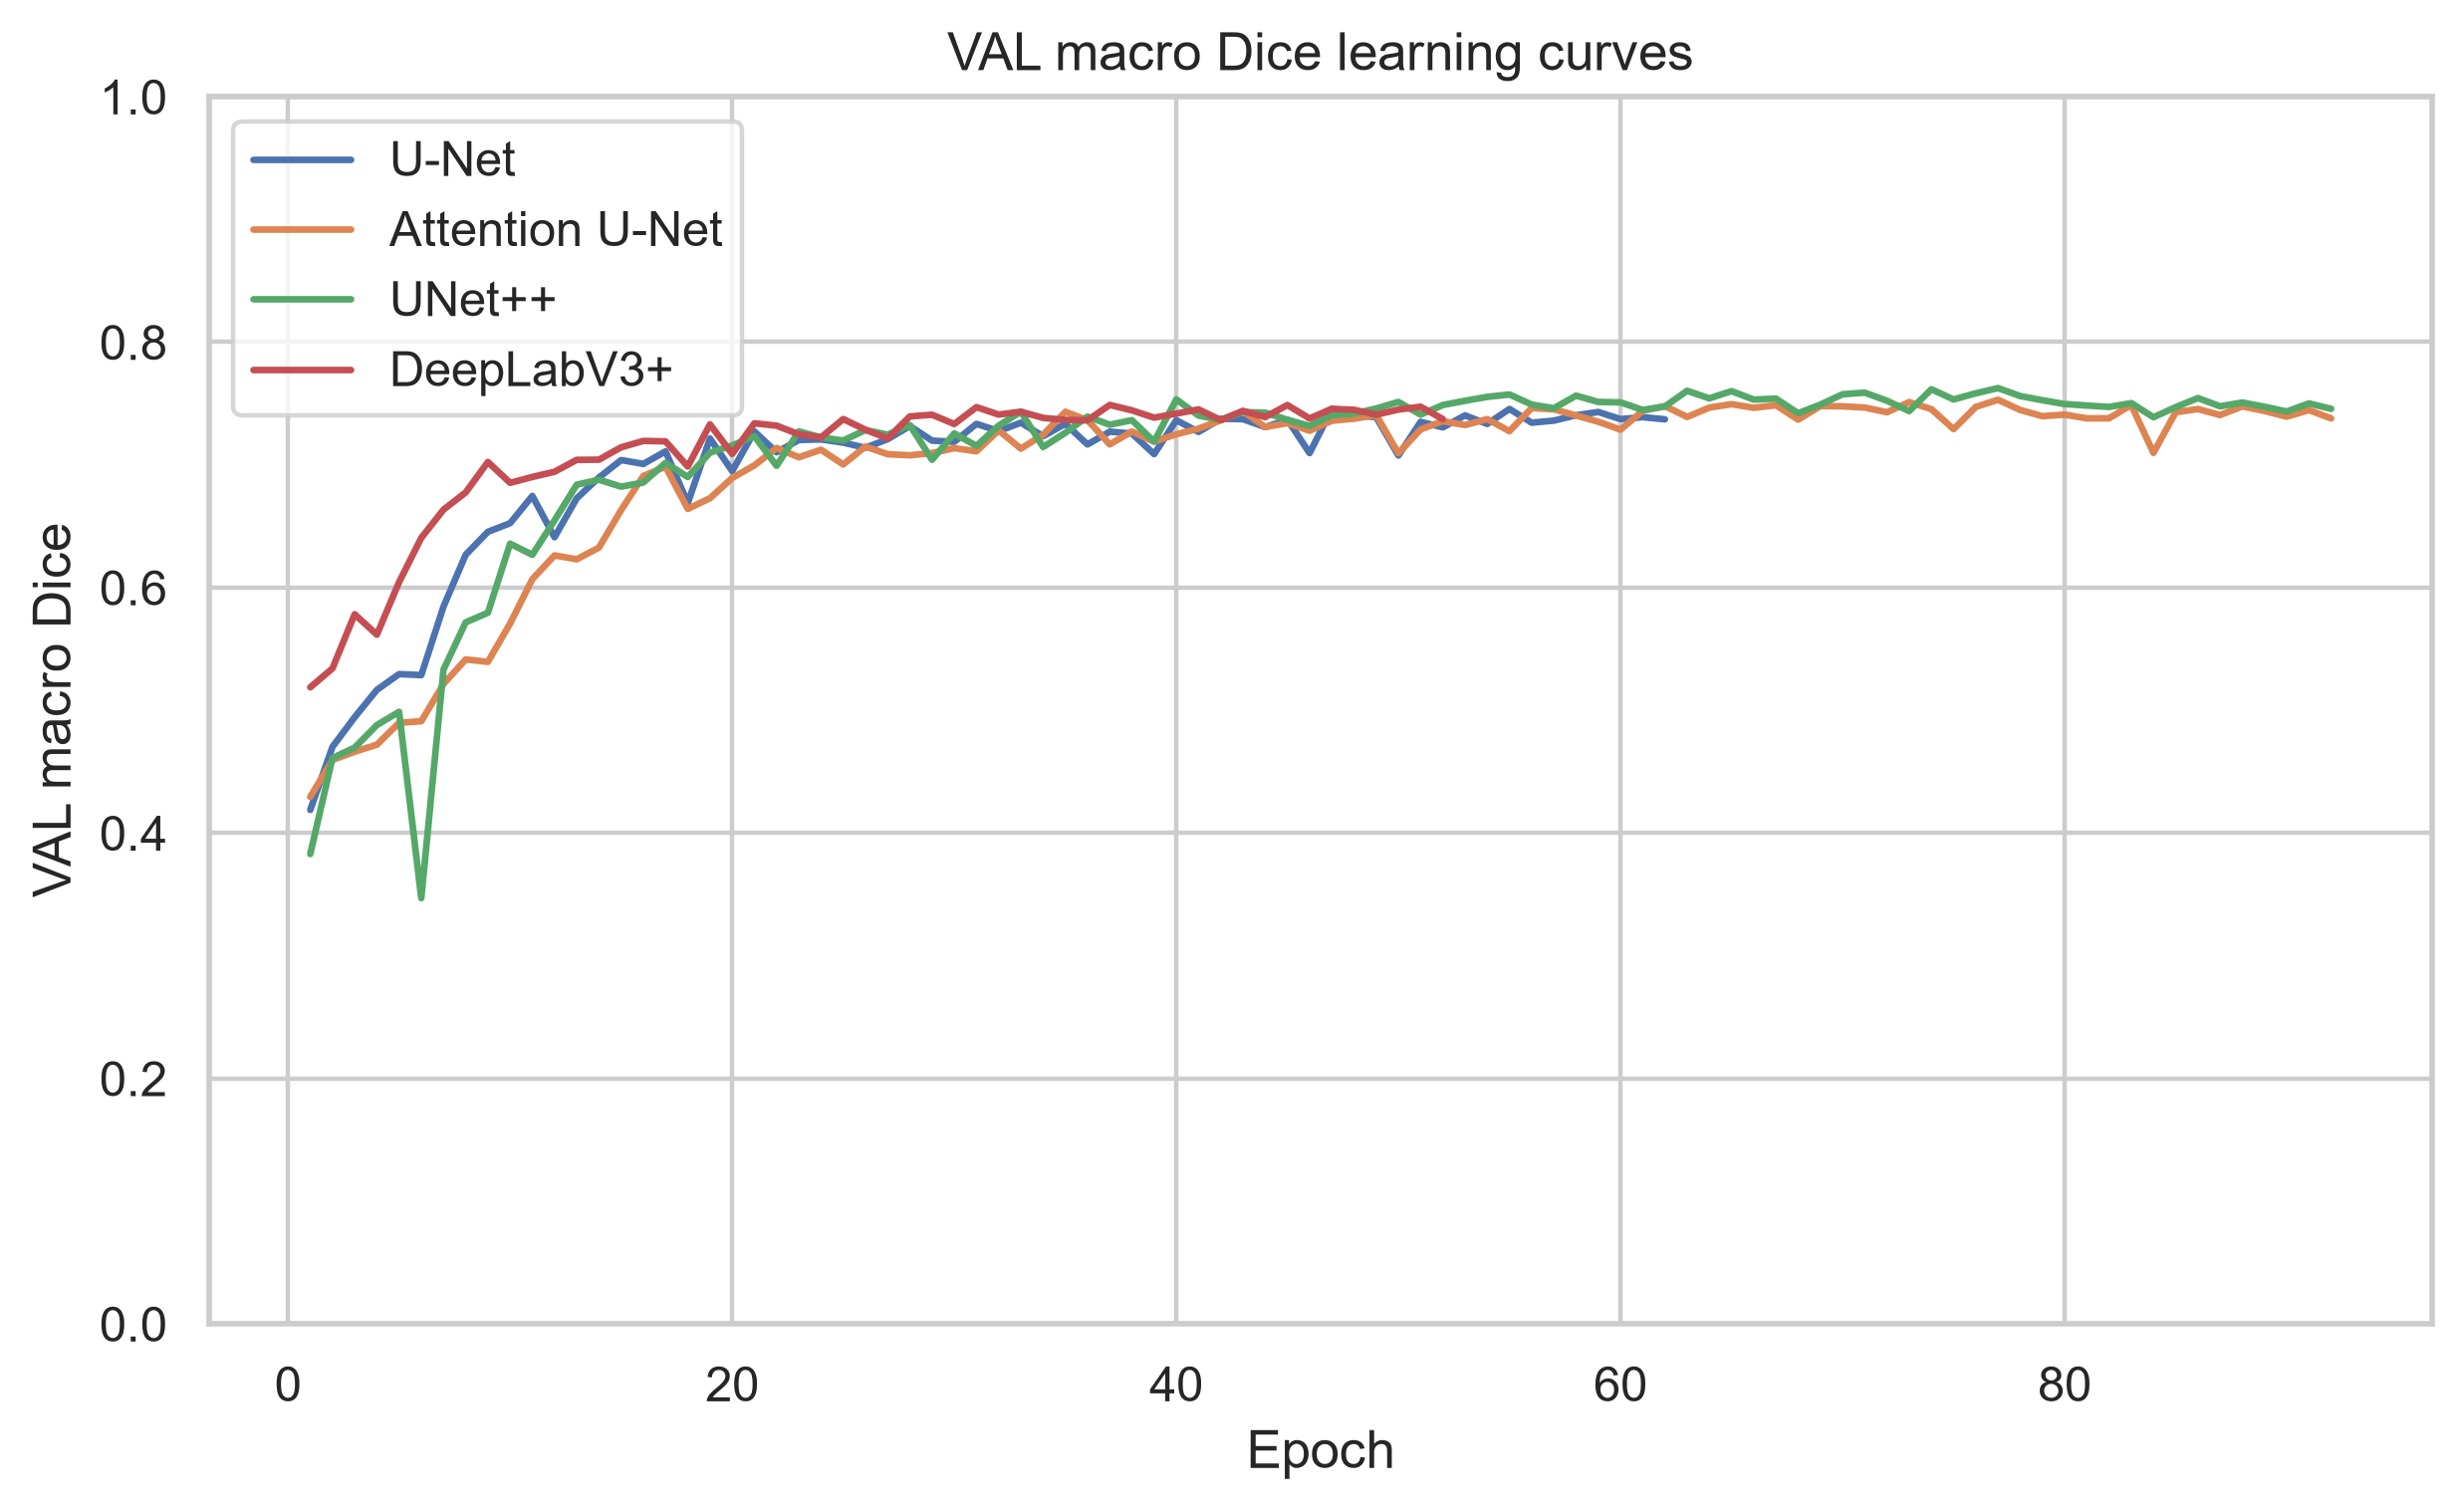

In [9]:
display(comparison[['model','parameters','training_wall_time','mean_epoch_time','peak_gpu_allocated','peak_gpu_reserved']])
display(Image(filename=str(F/'phase10_parameters_vs_dice.png'),width=850))
display(Image(filename=str(F/'phase10_training_efficiency.png'),width=950))
display(Image(filename=str(F/'phase10_val_dice_learning_curves.png'),width=950))

## Common-sample qualitative comparison

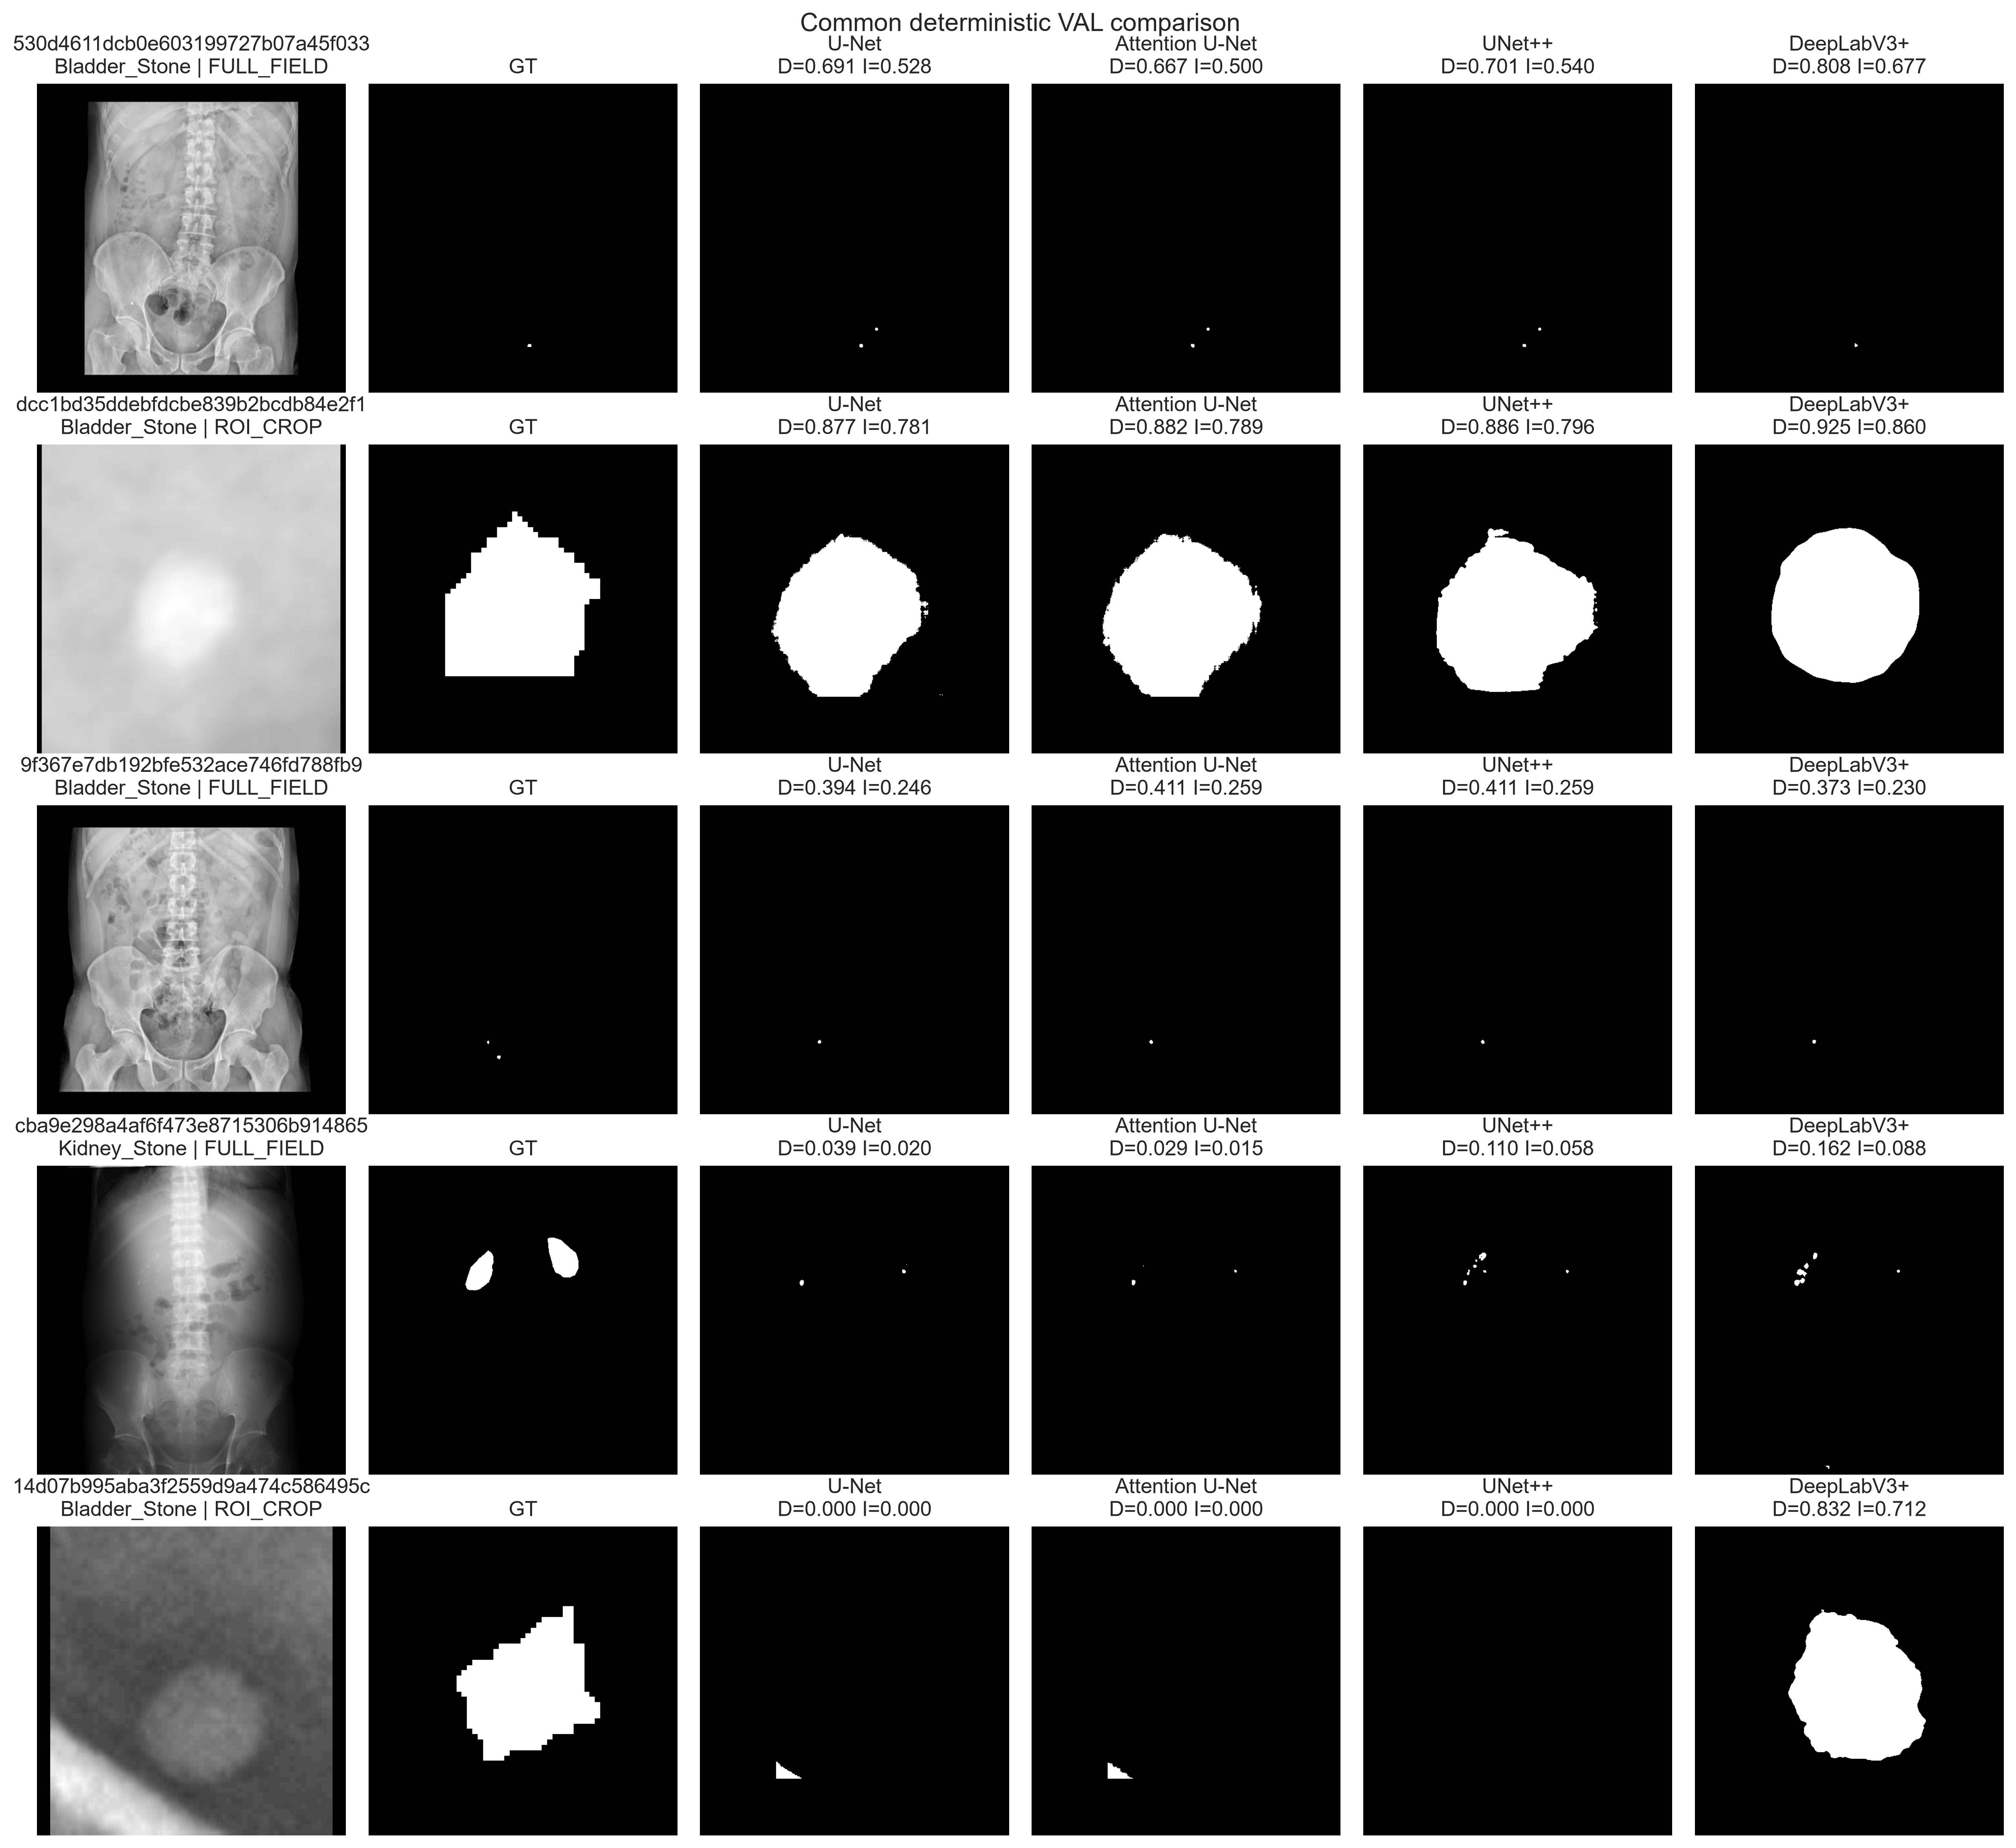

In [10]:
display(Image(filename=str(Q/'phase10_common_sample_comparison.png'),width=1200))

## Deterministic failure comparison

,sample_id,model,category,FOV,Dice,IoU,FP_Components
0,14d07b995aba3f2559d9a474c586495c,U-Net,Bladder_Stone,ROI_CROP,2.715768e-12,2.715768e-12,1
1,14d07b995aba3f2559d9a474c586495c,Attention U-Net,Bladder_Stone,ROI_CROP,2.714441e-12,2.714441e-12,1
2,14d07b995aba3f2559d9a474c586495c,UNet++,Bladder_Stone,ROI_CROP,2.758925e-12,2.758925e-12,0
3,14d07b995aba3f2559d9a474c586495c,DeepLabV3+,Bladder_Stone,ROI_CROP,8.319670e-01,7.122804e-01,0
4,501570377c27ca3a1b04f8e78ebbaa45,U-Net,Kidney_Stone,FULL_FIELD,3.048780e-10,3.048780e-10,0
5,501570377c27ca3a1b04f8e78ebbaa45,Attention U-Net,Kidney_Stone,FULL_FIELD,2.890173e-10,2.890173e-10,1
6,501570377c27ca3a1b04f8e78ebbaa45,UNet++,Kidney_Stone,FULL_FIELD,2.881844e-10,2.881844e-10,1
7,501570377c27ca3a1b04f8e78ebbaa45,DeepLabV3+,Kidney_Stone,FULL_FIELD,3.048780e-10,3.048780e-10,0
8,b2808e41b8867a697246a3f07d56ccf6,U-Net,Kidney_Stone,FULL_FIELD,3.215434e-10,3.215434e-10,1
9,b2808e41b8867a697246a3f07d56ccf6,Attention U-Net,Kidney_Stone,FULL_FIELD,3.424658e-10,3.424658e-10,1


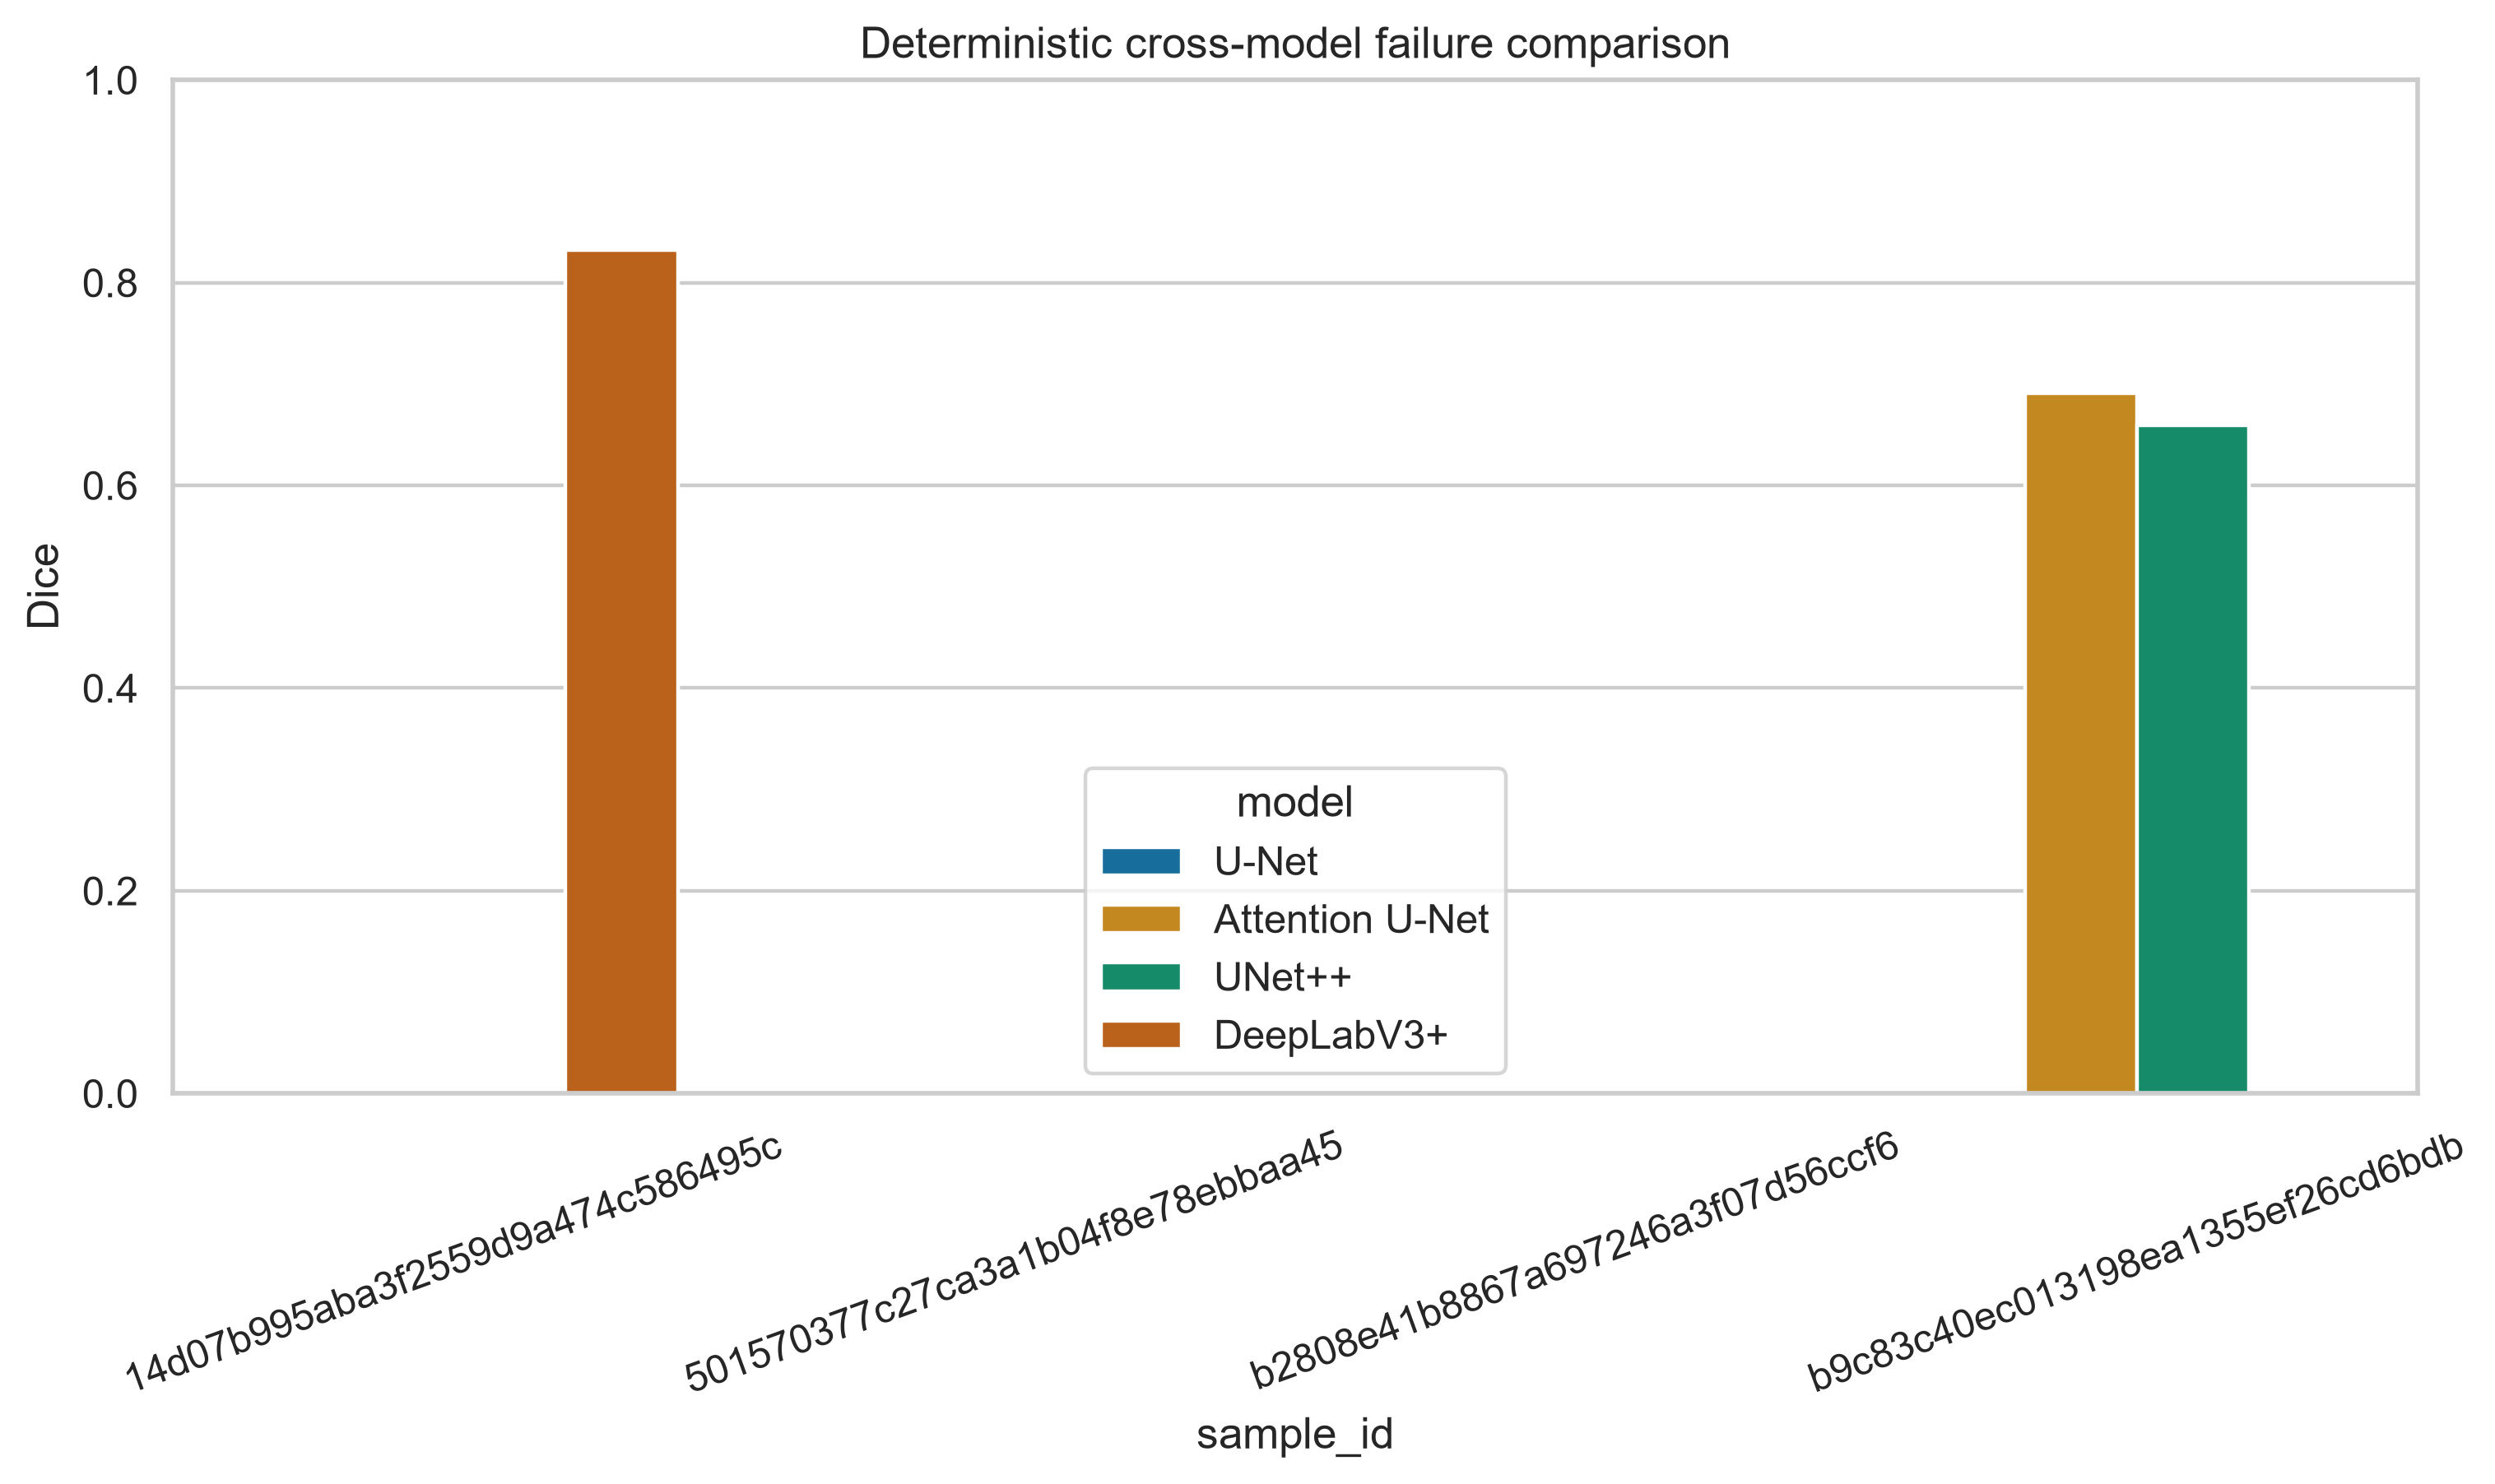

In [11]:
display(pd.read_csv(T/'phase10_kub_failure_comparison.csv'))
display(Image(filename=str(Q/'phase10_failure_comparison.png'),width=1000))

## Limitations

Single seed (42), one internal validation split, and descriptive comparisons only. No formal significance or causality claims are made. Original-space `kub_size_v1` and 512×512 evaluation-space object counts are explicitly distinct.

## Phase control

**TEST NOT ACCESSED. Phase 10 complete. STOP. Phase 11 requires explicit authorization.**